# Exploratory Data Analysis

## Objective

This notebook explores the seven source tables in the European Soccer Database before final cleaning and modelling.

We use exploratory data analysis (EDA) to understand:

- what one row represents in each table,
- where values are missing or repeated,
- how match outcomes, goals, leagues and seasons differ,
- how team tactics and player ratings are distributed, and
- which data-quality issues may affect the machine-learning task.

**Inputs:** the CSV files in `data/extracted` created from the original relational database.

**Outputs:** selected summary tables in `outputs/tables` and report-quality figures in `outputs/figures`.

Notebook 01 created the engineered match-level dataset. This notebook focuses on understanding the source data and does **not** perform final cleaning, feature selection or modelling. Its findings guide the decisions documented in Notebook 03.

> **Temporal scope:** descriptive EDA uses the complete raw history so that data-quality issues can be seen. No model is fitted and no feature or hyperparameter is selected from the test-season results. Later modelling must continue to keep the 2015/2016 test season untouched.


## 1. Imports and Project Paths

We first import the analysis libraries and define every path from the project root. Using `Path` objects avoids depending on whether Jupyter was started from the repository root or from the `notebooks` folder.


In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns


# Locate the repository whether Jupyter starts in the root or notebooks folder.
def find_project_root(start=Path.cwd()):
    for candidate in (start, *start.parents):
        if (candidate / "data/extracted").exists():
            return candidate
    raise FileNotFoundError(
        "Could not locate a project root containing data/extracted."
    )


PROJECT_ROOT = find_project_root()

RAW_DIR = PROJECT_ROOT / "data" / "extracted"
FIGURES_DIR = PROJECT_ROOT / "outputs" / "figures"
TABLES_DIR = PROJECT_ROOT / "outputs" / "tables"

FIGURES_DIR.mkdir(parents=True, exist_ok=True)
TABLES_DIR.mkdir(parents=True, exist_ok=True)

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 120

print("Project root:", PROJECT_ROOT)
print("Source data:", RAW_DIR)
print("Figures:", FIGURES_DIR)
print("Tables:", TABLES_DIR)


Matplotlib is building the font cache; this may take a moment.


Project root resolved successfully.
Source data: data/extracted
Figures: outputs/figures
Tables: outputs/tables


## 2. Load the Source Tables

The database contains three kinds of tables:

- **Historical transaction table:** `Match` has one row per match.
- **Reference/entity tables:** `Country`, `League`, `Team` and `Player` identify real-world entities.
- **Time-varying attribute tables:** `Team_Attributes` and `Player_Attributes` can contain many dated rows for the same team or player.

Repeated team or player IDs in an attribute table are therefore expected historical observations, not automatic duplicates.


In [2]:
match_df = pd.read_csv(RAW_DIR / "Match.csv")
team_df = pd.read_csv(RAW_DIR / "Team.csv")
team_attributes_df = pd.read_csv(RAW_DIR / "Team_Attributes.csv")
player_df = pd.read_csv(RAW_DIR / "Player.csv")
player_attributes_df = pd.read_csv(RAW_DIR / "Player_Attributes.csv")
league_df = pd.read_csv(RAW_DIR / "League.csv")
country_df = pd.read_csv(RAW_DIR / "Country.csv")

source_tables = {
    "Match": match_df,
    "Team": team_df,
    "Team_Attributes": team_attributes_df,
    "Player": player_df,
    "Player_Attributes": player_attributes_df,
    "League": league_df,
    "Country": country_df,
}

source_overview = pd.DataFrame(
    [
        {"table": name, "rows": len(frame), "columns": frame.shape[1]}
        for name, frame in source_tables.items()
    ]
)

display(source_overview)


,table,rows,columns
0,Match,25979,115
1,Team,299,5
2,Team_Attributes,1458,25
3,Player,11060,7
4,Player_Attributes,183978,42
5,League,11,3
6,Country,11,2


### Finding

The tables have very different sizes and roles. `Match` is wide because it includes line-ups, match events and betting odds. `Player_Attributes` is the largest by row count because each player can have many dated ratings. The League and Country tables are small lookups.


## 3. Match Table

One row in `Match` represents one played fixture. It identifies the league, season, date, home and away teams, final score, line-up information, match events and bookmaker odds.

For prediction, the final score is used to create the target class—Home Win, Draw or Away Win—but it must never be used as an input feature for that same match.


### 3.1 Structure

The raw table has many columns, so a focused preview is more useful than displaying all 115 columns. We inspect the identifiers, date, teams and final score that define a match.


In [3]:
match_core_columns = [
    "id",
    "country_id",
    "league_id",
    "season",
    "stage",
    "date",
    "match_api_id",
    "home_team_api_id",
    "away_team_api_id",
    "home_team_goal",
    "away_team_goal",
]

match_structure = pd.DataFrame(
    {
        "rows": [match_df.shape[0]],
        "columns": [match_df.shape[1]],
        "numeric_columns": [match_df.select_dtypes(include="number").shape[1]],
        "text_columns": [
            match_df.select_dtypes(include=["object", "string"]).shape[1]
        ],
    }
)

display(match_structure)
display(match_df[match_core_columns].head())


,rows,columns,numeric_columns,text_columns
0,25979,115,105,10


,id,country_id,league_id,season,stage,date,match_api_id,home_team_api_id,away_team_api_id,home_team_goal,away_team_goal
0,1,1,1,2008/2009,1,2008-08-17 00:00:00,492473,9987,9993,1,1
1,2,1,1,2008/2009,1,2008-08-16 00:00:00,492474,10000,9994,0,0
2,3,1,1,2008/2009,1,2008-08-16 00:00:00,492475,9984,8635,0,3
3,4,1,1,2008/2009,1,2008-08-17 00:00:00,492476,9991,9998,5,0
4,5,1,1,2008/2009,1,2008-08-16 00:00:00,492477,7947,9985,1,3


### 3.2 Missing Values

Missing data is not equally important in every column. Missing bookmaker odds or XML event details do not mean that the match itself is unusable. We therefore summarize all missingness, then separately check the core fields needed to identify teams, dates and outcomes.


In [4]:
match_missing = pd.DataFrame(
    {
        "missing_count": match_df.isna().sum(),
        "missing_percentage": match_df.isna().mean() * 100,
    }
)
match_missing.index.name = "column"
match_missing = match_missing.sort_values(
    ["missing_count", "column"], ascending=[False, True]
)

match_missing.reset_index().to_csv(
    TABLES_DIR / "match_missing_values.csv", index=False
)

match_missing_overview = pd.DataFrame(
    {
        "total_columns": [match_df.shape[1]],
        "complete_columns": [(match_missing["missing_count"] == 0).sum()],
        "columns_with_missing_values": [
            (match_missing["missing_count"] > 0).sum()
        ],
    }
)

display(match_missing_overview)
display(match_missing.query("missing_count > 0").head(20).round(2))
display(match_df[match_core_columns].isna().sum().rename("missing_count"))


,total_columns,complete_columns,columns_with_missing_values
0,115,11,104


,missing_count,missing_percentage
column,,
PSA,14811,57.01
PSD,14811,57.01
PSH,14811,57.01
BSA,11818,45.49
BSD,11818,45.49
BSH,11818,45.49
GBA,11817,45.49
GBD,11817,45.49
GBH,11817,45.49


column
id                  0
country_id          0
league_id           0
season              0
stage               0
date                0
match_api_id        0
home_team_api_id    0
away_team_api_id    0
home_team_goal      0
away_team_goal      0
Name: missing_count, dtype: int64

### Finding

The table contains missing values in 104 of its 115 columns, concentrated in optional event, formation, player and betting fields. In contrast, all core match identifiers, dates, team IDs and final goals are complete. Later preprocessing should choose fields by their modelling role rather than dropping every row with any missing value.


### 3.3 Duplicates and Basic Validity

We distinguish duplicate rows and duplicate match identifiers from valid repeated league, season and team identifiers. We also check impossible-looking conditions such as a team playing itself or negative goals.


In [5]:
match_quality = pd.DataFrame(
    {
        "check": [
            "Total matches",
            "Duplicate match IDs",
            "Duplicate rows",
            "Missing home team IDs",
            "Missing away team IDs",
            "Missing home goals",
            "Missing away goals",
            "Same team listed home and away",
            "Rows with a negative goal value",
        ],
        "value": [
            len(match_df),
            match_df["id"].duplicated().sum(),
            match_df.duplicated().sum(),
            match_df["home_team_api_id"].isna().sum(),
            match_df["away_team_api_id"].isna().sum(),
            match_df["home_team_goal"].isna().sum(),
            match_df["away_team_goal"].isna().sum(),
            (
                match_df["home_team_api_id"]
                == match_df["away_team_api_id"]
            ).sum(),
            (
                (match_df["home_team_goal"] < 0)
                | (match_df["away_team_goal"] < 0)
            ).sum(),
        ],
    }
)

match_quality.to_csv(TABLES_DIR / "match_data_quality.csv", index=False)
display(match_quality)


,check,value
0,Total matches,25979
1,Duplicate match IDs,0
2,Duplicate rows,0
3,Missing home team IDs,0
4,Missing away team IDs,0
5,Missing home goals,0
6,Missing away goals,0
7,Same team listed home and away,0
8,Rows with a negative goal value,0


### Finding

There are 25,979 matches, with no duplicate match IDs, duplicate rows, same-team fixtures, missing final scores or negative goals. This supports using `id` as a row identifier, but identifiers themselves should not be treated as continuous predictive measurements.


### 3.4 Match Outcomes and Class Balance

The prediction target has three classes. Examining their frequencies shows whether a simple accuracy score could hide weak performance on a smaller class.


,result,matches,percentage
0,Home Win,11917,45.87
1,Draw,6596,25.39
2,Away Win,7466,28.74


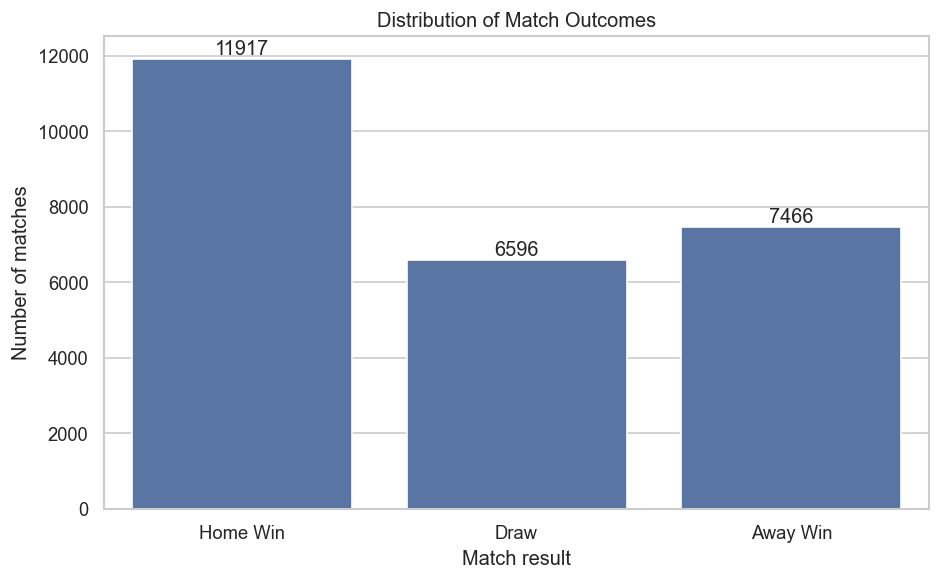

In [6]:
# Work with a compact copy so new EDA columns do not fragment the wide raw table.
match_analysis = match_df[match_core_columns].copy()
match_analysis["date"] = pd.to_datetime(match_analysis["date"])

match_analysis["result"] = "Draw"
match_analysis.loc[
    match_analysis["home_team_goal"] > match_analysis["away_team_goal"],
    "result",
] = "Home Win"
match_analysis.loc[
    match_analysis["home_team_goal"] < match_analysis["away_team_goal"],
    "result",
] = "Away Win"

outcome_order = ["Home Win", "Draw", "Away Win"]
outcome_counts = match_analysis["result"].value_counts().reindex(outcome_order)
outcome_summary = pd.DataFrame(
    {
        "result": outcome_order,
        "matches": outcome_counts.values,
        "percentage": (outcome_counts.values / len(match_analysis)) * 100,
    }
)

display(outcome_summary.round(2))

plt.figure(figsize=(8, 5))
ax = sns.barplot(
    data=outcome_summary,
    x="result",
    y="matches",
    color="#4C72B0",
)
ax.bar_label(ax.containers[0], fmt="%.0f")
plt.title("Distribution of Match Outcomes")
plt.xlabel("Match result")
plt.ylabel("Number of matches")
plt.tight_layout()
plt.savefig(
    FIGURES_DIR / "match_outcome_distribution.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()


### Finding

Home Wins are the largest class: 11,917 matches (45.87%), compared with 7,466 Away Wins (28.74%) and 6,596 Draws (25.39%). This is moderate class imbalance. Accuracy remains useful, but later modelling should use Macro F1 as the primary metric so that Draw and Away Win performance matters equally.


### 3.5 Goals, Home Advantage and Unusual Scores

Goal distributions provide another view of home advantage. We also inspect extreme scores. An unusual score is not automatically an error; it should be verified before any removal decision.


,count,mean,std,min,25%,50%,75%,max
column,,,,,,,,
home_team_goal,25979.0,1.545,1.297,0.0,1.0,1.0,2.0,10.0
away_team_goal,25979.0,1.161,1.142,0.0,0.0,1.0,2.0,9.0
total_goals,25979.0,2.706,1.672,0.0,2.0,3.0,4.0,12.0


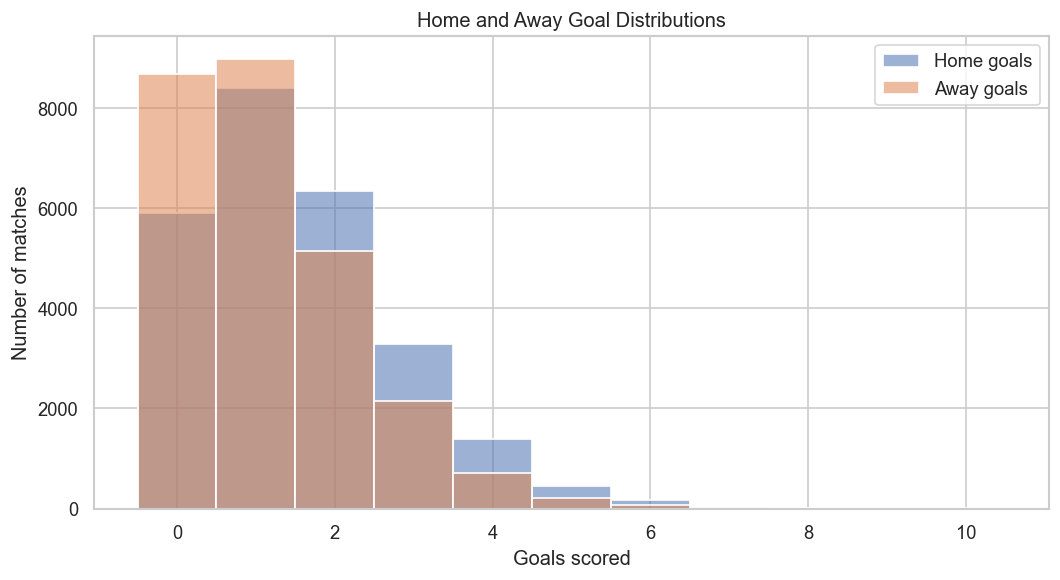

column,date,home_team_goal,away_team_goal,total_goals
24247,2015-12-20,10,2,12
9210,2013-03-30,9,2,11
13898,2010-10-24,10,0,10
2156,2009-11-22,9,1,10
24122,2014-09-20,2,8,10
20161,2010-11-06,9,0,9
7660,2016-03-13,0,9,9
8662,2011-05-07,1,8,9
22310,2010-11-20,0,8,8
24081,2015-05-02,0,8,8


In [7]:
match_analysis["total_goals"] = (
    match_analysis["home_team_goal"] + match_analysis["away_team_goal"]
)
match_analysis["home_win"] = match_analysis["result"].eq("Home Win")

goal_summary = match_analysis[
    ["home_team_goal", "away_team_goal", "total_goals"]
].describe().T
display(goal_summary.round(3))

plt.figure(figsize=(9, 5))
sns.histplot(
    match_analysis["home_team_goal"],
    discrete=True,
    label="Home goals",
    alpha=0.55,
)
sns.histplot(
    match_analysis["away_team_goal"],
    discrete=True,
    label="Away goals",
    alpha=0.55,
)
plt.title("Home and Away Goal Distributions")
plt.xlabel("Goals scored")
plt.ylabel("Number of matches")
plt.legend()
plt.tight_layout()
plt.savefig(
    FIGURES_DIR / "home_away_goal_distributions.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()

extreme_home_scores = match_analysis.nlargest(5, "home_team_goal")
extreme_away_scores = match_analysis.nlargest(5, "away_team_goal")
extreme_scores = pd.concat(
    [extreme_home_scores, extreme_away_scores]
).drop_duplicates("id")

display(
    extreme_scores[
        ["date", "home_team_goal", "away_team_goal", "total_goals"]
    ].sort_values("total_goals", ascending=False)
)


### Finding

Home teams score 1.545 goals per match on average, compared with 1.161 for away teams—a difference of about 0.384 goals. The table also contains rare but possible scores as high as 10 home goals and 9 away goals. Because the values are non-negative and internally consistent, EDA should flag them rather than automatically delete them.


### 3.6 League Patterns

Leagues differ in schedule size, goal frequency and home-win rate. These differences may be useful context, but `league_id` is an identifier rather than a continuous number.


,matches,home_win_percentage,average_goals
league_name,,,
Belgium Jupiler League,1728,46.875,2.802
England Premier League,3040,45.724,2.711
France Ligue 1,3040,44.704,2.443
Germany 1. Bundesliga,2448,45.221,2.902
Italy Serie A,3017,46.636,2.617
Netherlands Eredivisie,2448,47.835,3.081
Poland Ekstraklasa,1920,45.312,2.425
Portugal Liga ZON Sagres,2052,44.250,2.535
Scotland Premier League,1824,41.667,2.634


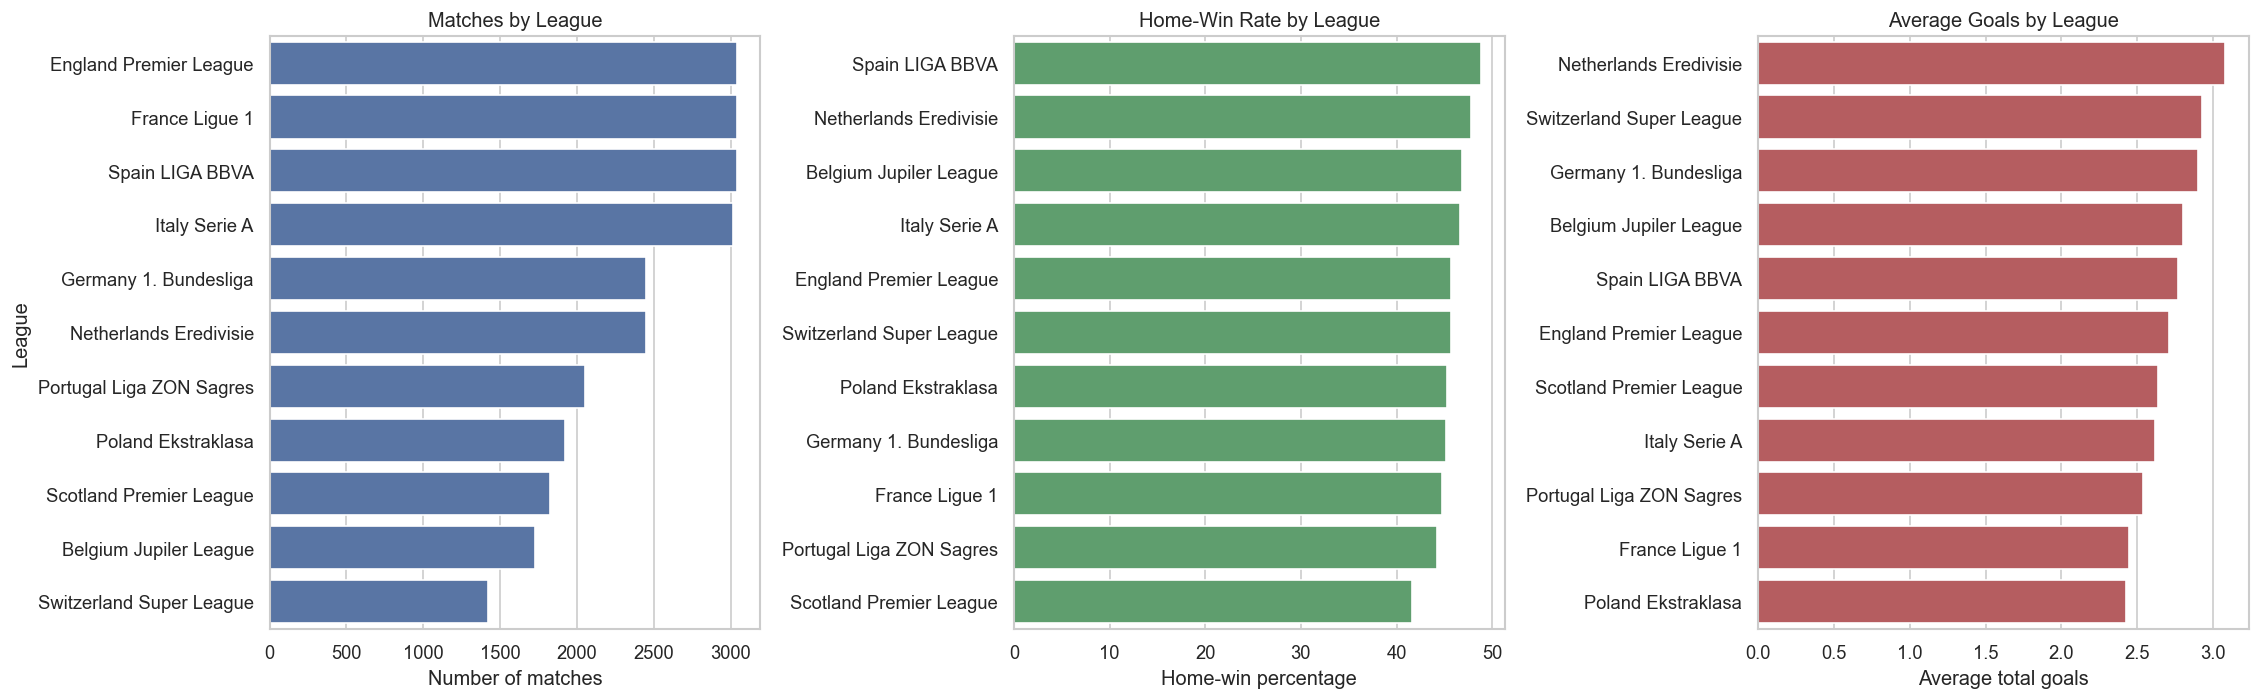

In [8]:
league_lookup = league_df.rename(
    columns={"id": "league_id", "name": "league_name"}
)[["league_id", "league_name"]]

match_league = match_analysis.merge(
    league_lookup,
    on="league_id",
    how="left",
    validate="many_to_one",
)

league_summary = (
    match_league.groupby("league_name")
    .agg(
        matches=("id", "size"),
        home_win_percentage=("home_win", lambda values: values.mean() * 100),
        average_goals=("total_goals", "mean"),
    )
    .sort_index()
)

league_summary.to_csv(TABLES_DIR / "league_summary.csv")
display(league_summary.round(3))

league_plot_data = league_summary.reset_index()
fig, axes = plt.subplots(1, 3, figsize=(19, 6))

sns.barplot(
    data=league_plot_data.sort_values("matches", ascending=False),
    x="matches",
    y="league_name",
    color="#4C72B0",
    ax=axes[0],
)
axes[0].set_title("Matches by League")
axes[0].set_xlabel("Number of matches")
axes[0].set_ylabel("League")

sns.barplot(
    data=league_plot_data.sort_values("home_win_percentage", ascending=False),
    x="home_win_percentage",
    y="league_name",
    color="#55A868",
    ax=axes[1],
)
axes[1].set_title("Home-Win Rate by League")
axes[1].set_xlabel("Home-win percentage")
axes[1].set_ylabel("")

sns.barplot(
    data=league_plot_data.sort_values("average_goals", ascending=False),
    x="average_goals",
    y="league_name",
    color="#C44E52",
    ax=axes[2],
)
axes[2].set_title("Average Goals by League")
axes[2].set_xlabel("Average total goals")
axes[2].set_ylabel("")

fig.tight_layout()
fig.savefig(
    FIGURES_DIR / "league_patterns.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()


### Finding

League coverage ranges from 1,422 matches in Switzerland to 3,040 in England, France and Spain. Spain has the highest home-win rate (48.85%), while Scotland has the lowest (41.67%). The Netherlands has the highest average goals (3.081), while Poland has the lowest (2.425). League context may therefore help prediction, but unequal league sizes should be remembered when comparing aggregate results.


### 3.7 Seasonal Trends

We examine match count, scoring and outcome shares across seasons. These are descriptive trends only; they are not used to select a model using the future test season.


,match_count,average_goals,home_win_percentage,draw_percentage,away_win_percentage
season,,,,,
2008/2009,3326,2.607,47.084,24.985,27.931
2009/2010,3230,2.672,47.430,25.201,27.368
2010/2011,3260,2.684,46.626,25.736,27.638
2011/2012,3220,2.716,46.522,25.404,28.075
2012/2013,3260,2.773,44.294,26.166,29.540
2013/2014,3032,2.767,46.306,24.274,29.420
2014/2015,3325,2.676,44.932,25.564,29.504
2015/2016,3326,2.755,43.867,25.707,30.427


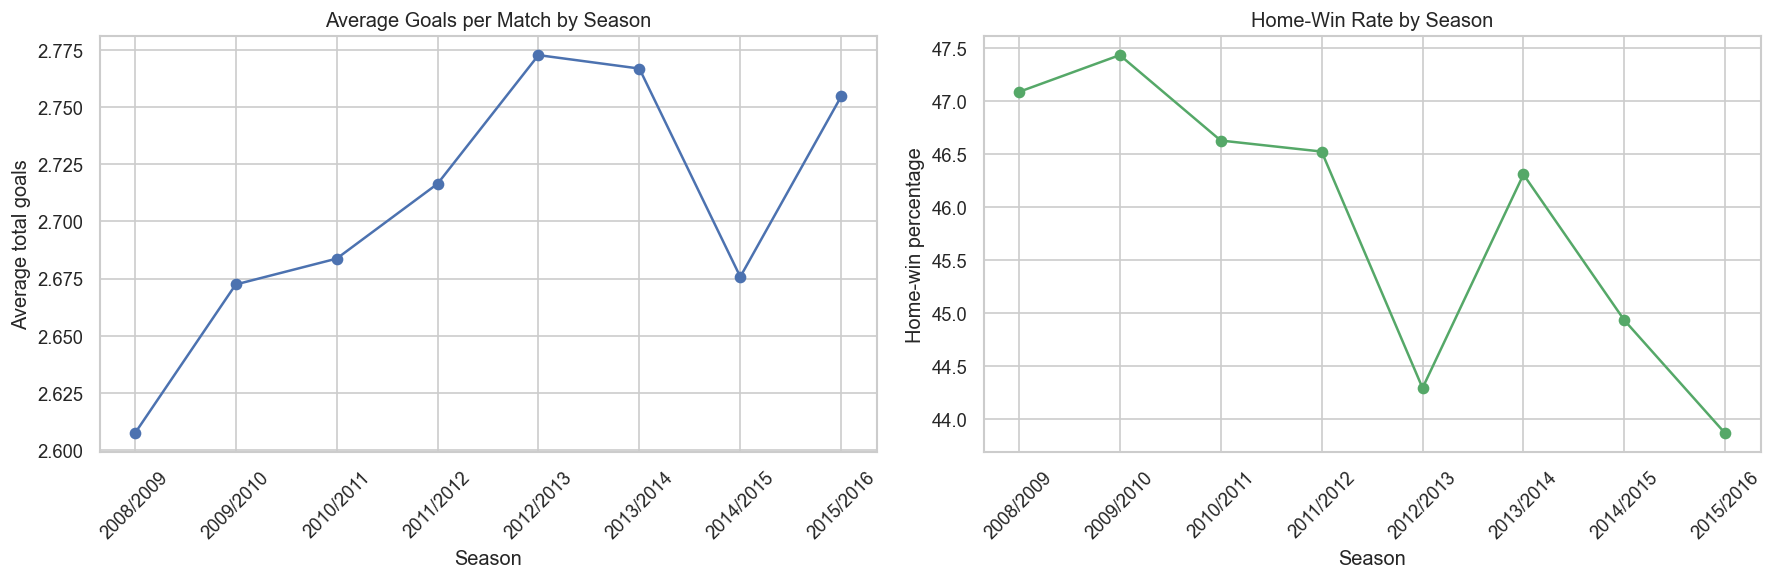

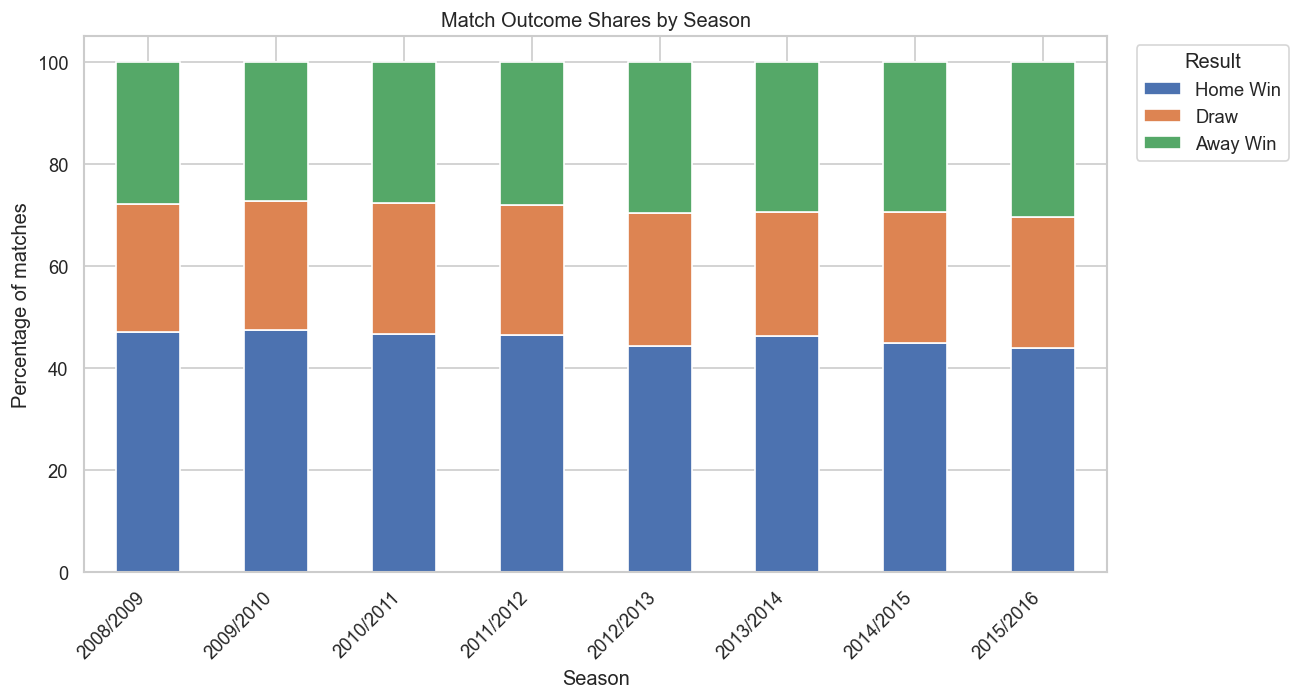

In [9]:
season_outcomes = pd.crosstab(
    match_analysis["season"],
    match_analysis["result"],
    normalize="index",
).mul(100)

season_summary = (
    match_analysis.groupby("season")
    .agg(
        match_count=("id", "size"),
        average_goals=("total_goals", "mean"),
        home_win_percentage=("home_win", lambda values: values.mean() * 100),
    )
    .join(
        season_outcomes[["Draw", "Away Win"]].rename(
            columns={
                "Draw": "draw_percentage",
                "Away Win": "away_win_percentage",
            }
        )
    )
)

season_summary.to_csv(TABLES_DIR / "season_summary.csv")
display(season_summary.round(3))

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
season_summary["average_goals"].plot(marker="o", ax=axes[0])
axes[0].set_title("Average Goals per Match by Season")
axes[0].set_xlabel("Season")
axes[0].set_ylabel("Average total goals")
axes[0].tick_params(axis="x", rotation=45)

season_summary["home_win_percentage"].plot(
    marker="o", color="#55A868", ax=axes[1]
)
axes[1].set_title("Home-Win Rate by Season")
axes[1].set_xlabel("Season")
axes[1].set_ylabel("Home-win percentage")
axes[1].tick_params(axis="x", rotation=45)

fig.tight_layout()
fig.savefig(
    FIGURES_DIR / "seasonal_goal_and_home_win_trends.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()

season_outcomes[["Home Win", "Draw", "Away Win"]].plot(
    kind="bar",
    stacked=True,
    figsize=(11, 6),
    color=["#4C72B0", "#DD8452", "#55A868"],
)
plt.title("Match Outcome Shares by Season")
plt.xlabel("Season")
plt.ylabel("Percentage of matches")
plt.legend(title="Result", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.savefig(
    FIGURES_DIR / "seasonal_outcome_shares.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()


### Match-Table Finding

Season sizes are fairly similar, ranging from 3,032 to 3,326 matches. Average goals peak at 2.773 in 2012/2013. The home-win share fluctuates and falls from 47.43% in 2009/2010 to 43.87% in 2015/2016, while the away-win share reaches 30.43% in 2015/2016. This shows that outcome proportions are not perfectly constant over time, which supports chronological rather than random evaluation later.


## 4. Team Table

One row in `Team` represents one team identity. `team_api_id` is the reliable key used by the Match and Team_Attributes tables; the team name is mainly for human-readable reporting.


### 4.1 Structure, Missing Values and Duplicates

We check whether IDs are unique, whether display names repeat, and whether every team referenced by a match exists in the lookup table.


In [10]:
display(team_df.head())

duplicate_team_names = team_df[
    team_df["team_long_name"].duplicated(keep=False)
].sort_values("team_long_name")
teams_missing_fifa_id = team_df.loc[
    team_df["team_fifa_api_id"].isna(),
    ["team_api_id", "team_long_name"],
]

team_id_linkage = pd.DataFrame(
    {
        "relationship": [
            "Home team IDs found in Team",
            "Away team IDs found in Team",
        ],
        "percentage_found": [
            match_df["home_team_api_id"].isin(team_df["team_api_id"]).mean()
            * 100,
            match_df["away_team_api_id"].isin(team_df["team_api_id"]).mean()
            * 100,
        ],
    }
)

team_summary = pd.DataFrame(
    {
        "total_teams": [len(team_df)],
        "missing_fifa_ids": [team_df["team_fifa_api_id"].isna().sum()],
        "duplicate_team_ids": [team_df["team_api_id"].duplicated().sum()],
        "duplicate_team_names": [
            team_df["team_long_name"].duplicated().sum()
        ],
    }
)

team_summary.to_csv(TABLES_DIR / "team_summary.csv", index=False)

display(team_df.isna().sum().rename("missing_count"))
display(team_summary)
display(duplicate_team_names)
display(teams_missing_fifa_id)
display(team_id_linkage)


,id,team_api_id,team_fifa_api_id,team_long_name,team_short_name
0,1,9987,673.0,KRC Genk,GEN
1,2,9993,675.0,Beerschot AC,BAC
2,3,10000,15005.0,SV Zulte-Waregem,ZUL
3,4,9994,2007.0,Sporting Lokeren,LOK
4,5,9984,1750.0,KSV Cercle Brugge,CEB


id                   0
team_api_id          0
team_fifa_api_id    11
team_long_name       0
team_short_name      0
Name: missing_count, dtype: int64

,total_teams,missing_fifa_ids,duplicate_team_ids,duplicate_team_names
0,299,11,0,3


,id,team_api_id,team_fifa_api_id,team_long_name,team_short_name
182,31444,8031,111429.0,Polonia Bytom,POB
183,31445,8020,111429.0,Polonia Bytom,GOR
15,16,9996,111560.0,Royal Excel Mouscron,MOU
24,2510,274581,111560.0,Royal Excel Mouscron,MOP
189,31451,8244,301.0,Widzew Łódź,LOD
199,32409,8024,301.0,Widzew Łódź,WID


,team_api_id,team_long_name
8,7947,FCV Dender EH
14,4049,Tubize
170,6601,FC Volendam
204,177361,Termalica Bruk-Bet Nieciecza
208,7992,Trofense
213,10213,Amadora
223,9765,Portimonense
225,4064,Feirense
232,6367,Uniao da Madeira
233,188163,Tondela


,relationship,percentage_found
0,Home team IDs found in Team,100.0
1,Away team IDs found in Team,100.0


### Finding

There are 299 teams and every home and away team ID in Match resolves to this table. Eleven FIFA IDs are missing, but `team_api_id` is complete and unique. Three names repeat across different IDs, so a name alone must not be used as a join key or treated as proof of a duplicate team.


### 4.2 Historical Match Coverage by Team

Teams have different amounts of match history because of promotion, relegation and differences in league coverage. We summarize the full distribution rather than showing an arbitrary “top 10” when many teams are tied.


In [11]:
home_match_counts = match_df["home_team_api_id"].value_counts()
away_match_counts = match_df["away_team_api_id"].value_counts()
all_match_counts = home_match_counts.add(away_match_counts, fill_value=0)

team_match_count = team_df[["team_api_id", "team_long_name"]].copy()
team_match_count["matches"] = team_match_count["team_api_id"].map(
    all_match_counts
)

team_match_coverage = team_match_count["matches"].describe().to_frame(
    "matches"
)
teams_at_maximum = (
    team_match_count["matches"] == team_match_count["matches"].max()
).sum()

display(team_match_coverage)
print("Teams tied at the maximum match count:", teams_at_maximum)
display(team_match_count.nlargest(5, "matches"))
display(team_match_count.nsmallest(5, "matches"))


,matches
count,299.000000
mean,173.772575
std,96.448104
min,30.000000
25%,76.000000
50%,190.000000
75%,266.000000
max,304.000000


Teams tied at the maximum match count: 34


,team_api_id,team_long_name,matches
25,10260,Manchester United,304
27,9825,Arsenal,304
29,8472,Sunderland,304
30,8650,Liverpool,304
33,10252,Aston Villa,304


,team_api_id,team_long_name,matches
20,6351,KAS Eupen,30
204,177361,Termalica Bruk-Bet Nieciecza,30
208,7992,Trofense,30
213,10213,Amadora,30
223,9765,Portimonense,30


### Team-Table Finding

Team coverage ranges from 30 to 304 matches, with a median of 190. Thirty-four teams tie at the maximum of 304 matches. Models may have richer historical evidence for long-observed teams than for teams with short histories.


## 5. Team_Attributes Table

One row in `Team_Attributes` represents a team's tactical profile on a particular date. The same team can correctly appear several times as its tactics change.

For a match prediction, only the most recent attribute record dated **before** the match may be joined. Using a later record would leak future information.


### 5.1 Structure, History and Missing Values

We check row uniqueness, date coverage, team coverage and missingness. Repeated `team_api_id` values are expected; repeated row IDs or identical rows would be a data-quality problem.


In [12]:
team_attributes_analysis = team_attributes_df.copy()
team_attributes_analysis["date"] = pd.to_datetime(
    team_attributes_analysis["date"]
)

team_attribute_missing = pd.DataFrame(
    {
        "missing_count": team_attributes_analysis.isna().sum(),
        "missing_percentage": team_attributes_analysis.isna().mean() * 100,
    }
)
team_attribute_missing.index.name = "column"
team_attribute_missing.reset_index().to_csv(
    TABLES_DIR / "team_attributes_missing_values.csv", index=False
)

team_attribute_record_counts = team_attributes_analysis[
    "team_api_id"
].value_counts()
teams_without_attributes = team_df.loc[
    ~team_df["team_api_id"].isin(team_attributes_analysis["team_api_id"]),
    ["team_api_id", "team_long_name"],
]

team_attribute_quality = pd.DataFrame(
    {
        "measure": [
            "Rows",
            "Columns",
            "Duplicate rows",
            "Duplicate row IDs",
            "Teams represented",
            "Teams in Team lookup",
            "First record",
            "Last record",
            "Minimum records per team",
            "Median records per team",
            "Maximum records per team",
        ],
        "value": [
            team_attributes_analysis.shape[0],
            team_attributes_analysis.shape[1],
            team_attributes_analysis.duplicated().sum(),
            team_attributes_analysis["id"].duplicated().sum(),
            team_attributes_analysis["team_api_id"].nunique(),
            team_df["team_api_id"].nunique(),
            team_attributes_analysis["date"].min().date(),
            team_attributes_analysis["date"].max().date(),
            team_attribute_record_counts.min(),
            team_attribute_record_counts.median(),
            team_attribute_record_counts.max(),
        ],
    }
)

display(team_attributes_analysis.head())
display(team_attribute_quality)
display(
    team_attribute_missing.query("missing_count > 0").round(2)
)
display(teams_without_attributes)


column,id,team_fifa_api_id,team_api_id,date,buildUpPlaySpeed,buildUpPlaySpeedClass,buildUpPlayDribbling,buildUpPlayDribblingClass,buildUpPlayPassing,buildUpPlayPassingClass,...,chanceCreationShooting,chanceCreationShootingClass,chanceCreationPositioningClass,defencePressure,defencePressureClass,defenceAggression,defenceAggressionClass,defenceTeamWidth,defenceTeamWidthClass,defenceDefenderLineClass
0,1,434,9930,2010-02-22,60,Balanced,NaN,Little,50,Mixed,...,55,Normal,Organised,50,Medium,55,Press,45,Normal,Cover
1,2,434,9930,2014-09-19,52,Balanced,48.0,Normal,56,Mixed,...,64,Normal,Organised,47,Medium,44,Press,54,Normal,Cover
2,3,434,9930,2015-09-10,47,Balanced,41.0,Normal,54,Mixed,...,64,Normal,Organised,47,Medium,44,Press,54,Normal,Cover
3,4,77,8485,2010-02-22,70,Fast,NaN,Little,70,Long,...,70,Lots,Organised,60,Medium,70,Double,70,Wide,Cover
4,5,77,8485,2011-02-22,47,Balanced,NaN,Little,52,Mixed,...,52,Normal,Organised,47,Medium,47,Press,52,Normal,Cover


,measure,value
0,Rows,1458
1,Columns,25
2,Duplicate rows,0
3,Duplicate row IDs,0
4,Teams represented,288
5,Teams in Team lookup,299
6,First record,2010-02-22
7,Last record,2015-09-10
8,Minimum records per team,1
9,Median records per team,6.0


,missing_count,missing_percentage
column,,
buildUpPlayDribbling,969,66.46


,team_api_id,team_long_name
8,7947,FCV Dender EH
14,4049,Tubize
170,6601,FC Volendam
204,177361,Termalica Bruk-Bet Nieciecza
208,7992,Trofense
213,10213,Amadora
223,9765,Portimonense
225,4064,Feirense
232,6367,Uniao da Madeira
233,188163,Tondela


### Finding

The table has 1,458 unique historical rows for 288 teams, compared with 299 teams in the Team lookup. A team has between 1 and 6 records, so repeated team IDs are valid time observations. Records span 22 February 2010 to 10 September 2015. `buildUpPlayDribbling` is the only incomplete column, with 969 missing values (66.46%), which explains why it was not used in the engineered feature set.


### 5.2 Tactical Distributions

The selected numerical attributes describe build-up play, chance creation and defending. Their distributions show typical ranges and whether a feature is concentrated around only a few values.


column,buildUpPlaySpeed,buildUpPlayPassing,chanceCreationPassing,chanceCreationCrossing,chanceCreationShooting,defencePressure,defenceAggression,defenceTeamWidth
count,1458.00,1458.00,1458.00,1458.00,1458.00,1458.00,1458.00,1458.00
mean,52.46,48.49,52.17,53.73,53.97,46.02,49.25,52.19
std,11.55,10.90,10.36,11.09,10.33,10.23,9.74,9.57
min,20.00,20.00,21.00,20.00,22.00,23.00,24.00,29.00
25%,45.00,40.00,46.00,47.00,48.00,39.00,44.00,47.00
50%,52.00,50.00,52.00,53.00,53.00,45.00,48.00,52.00
75%,62.00,55.00,59.00,62.00,61.00,51.00,55.00,58.00
max,80.00,80.00,80.00,80.00,80.00,72.00,72.00,73.00


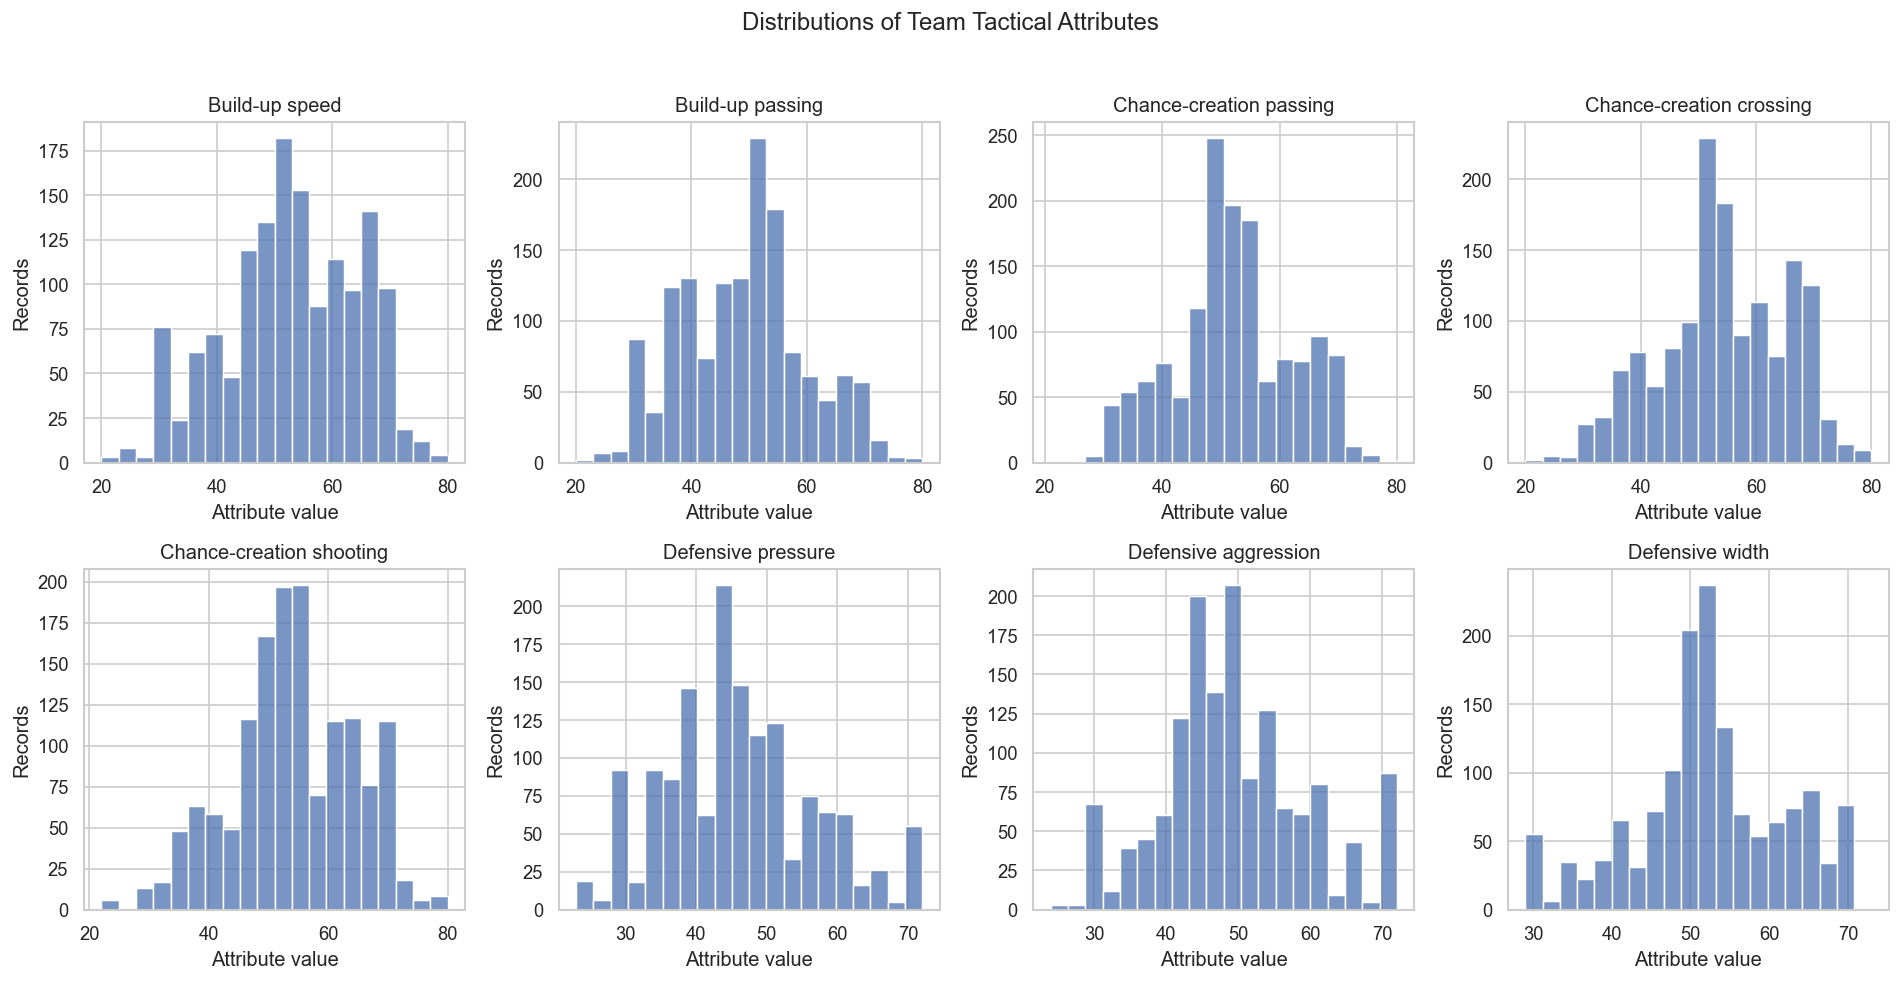

,defensive_line_style,records
0,Cover,1362
1,Offside Trap,96


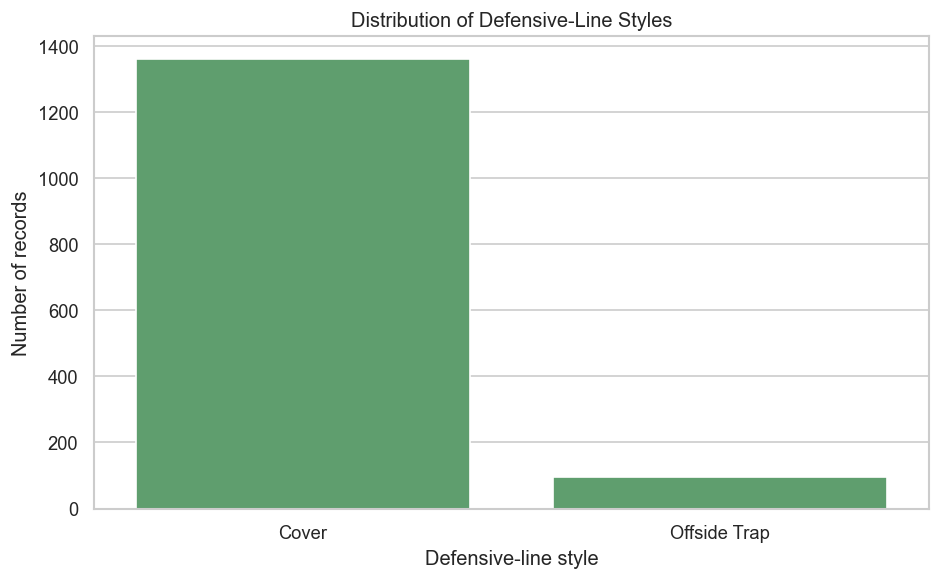

In [13]:
tactical_features = [
    "buildUpPlaySpeed",
    "buildUpPlayPassing",
    "chanceCreationPassing",
    "chanceCreationCrossing",
    "chanceCreationShooting",
    "defencePressure",
    "defenceAggression",
    "defenceTeamWidth",
]

tactical_labels = {
    "buildUpPlaySpeed": "Build-up speed",
    "buildUpPlayPassing": "Build-up passing",
    "chanceCreationPassing": "Chance-creation passing",
    "chanceCreationCrossing": "Chance-creation crossing",
    "chanceCreationShooting": "Chance-creation shooting",
    "defencePressure": "Defensive pressure",
    "defenceAggression": "Defensive aggression",
    "defenceTeamWidth": "Defensive width",
}

team_attributes_summary = team_attributes_analysis[
    tactical_features
].describe()
team_attributes_summary.to_csv(
    TABLES_DIR / "team_attributes_summary.csv"
)
display(team_attributes_summary.round(2))

fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for feature, axis in zip(tactical_features, axes.ravel()):
    sns.histplot(
        team_attributes_analysis[feature], bins=20, color="#4C72B0", ax=axis
    )
    axis.set_title(tactical_labels[feature])
    axis.set_xlabel("Attribute value")
    axis.set_ylabel("Records")

fig.suptitle("Distributions of Team Tactical Attributes", y=1.02)
fig.tight_layout()
fig.savefig(
    FIGURES_DIR / "team_tactical_distributions.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()

defensive_line_counts = (
    team_attributes_analysis["defenceDefenderLineClass"]
    .value_counts()
    .rename_axis("defensive_line_style")
    .reset_index(name="records")
)
display(defensive_line_counts)

plt.figure(figsize=(8, 5))
sns.barplot(
    data=defensive_line_counts,
    x="defensive_line_style",
    y="records",
    color="#55A868",
)
plt.title("Distribution of Defensive-Line Styles")
plt.xlabel("Defensive-line style")
plt.ylabel("Number of records")
plt.tight_layout()
plt.savefig(
    FIGURES_DIR / "defensive_line_styles.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()


### Finding

The tactical scores mostly fall between 20 and 80 and are centred near 45–55, although their shapes differ. Defensive-line style is highly uneven: 1,362 records use Cover and only 96 use Offside Trap. These values describe tactics, not match outcomes, and must still be joined using their historical dates.


### 5.3 Correlation Between Tactical Attributes

Correlation measures how strongly two numerical variables move together. High correlation can indicate redundant information, but EDA alone is not a reason to discard a feature.


column,buildUpPlaySpeed,buildUpPlayPassing,chanceCreationPassing,chanceCreationCrossing,chanceCreationShooting,defencePressure,defenceAggression,defenceTeamWidth
column,,,,,,,,
buildUpPlaySpeed,1.00,0.40,0.32,0.19,0.07,0.05,0.16,0.07
buildUpPlayPassing,0.40,1.00,0.22,0.23,-0.08,-0.05,0.12,0.06
chanceCreationPassing,0.32,0.22,1.00,0.25,0.11,0.20,0.15,0.15
chanceCreationCrossing,0.19,0.23,0.25,1.00,-0.01,0.09,0.10,0.13
chanceCreationShooting,0.07,-0.08,0.11,-0.01,1.00,0.19,0.12,0.13
defencePressure,0.05,-0.05,0.20,0.09,0.19,1.00,0.42,0.51
defenceAggression,0.16,0.12,0.15,0.10,0.12,0.42,1.00,0.24
defenceTeamWidth,0.07,0.06,0.15,0.13,0.13,0.51,0.24,1.00


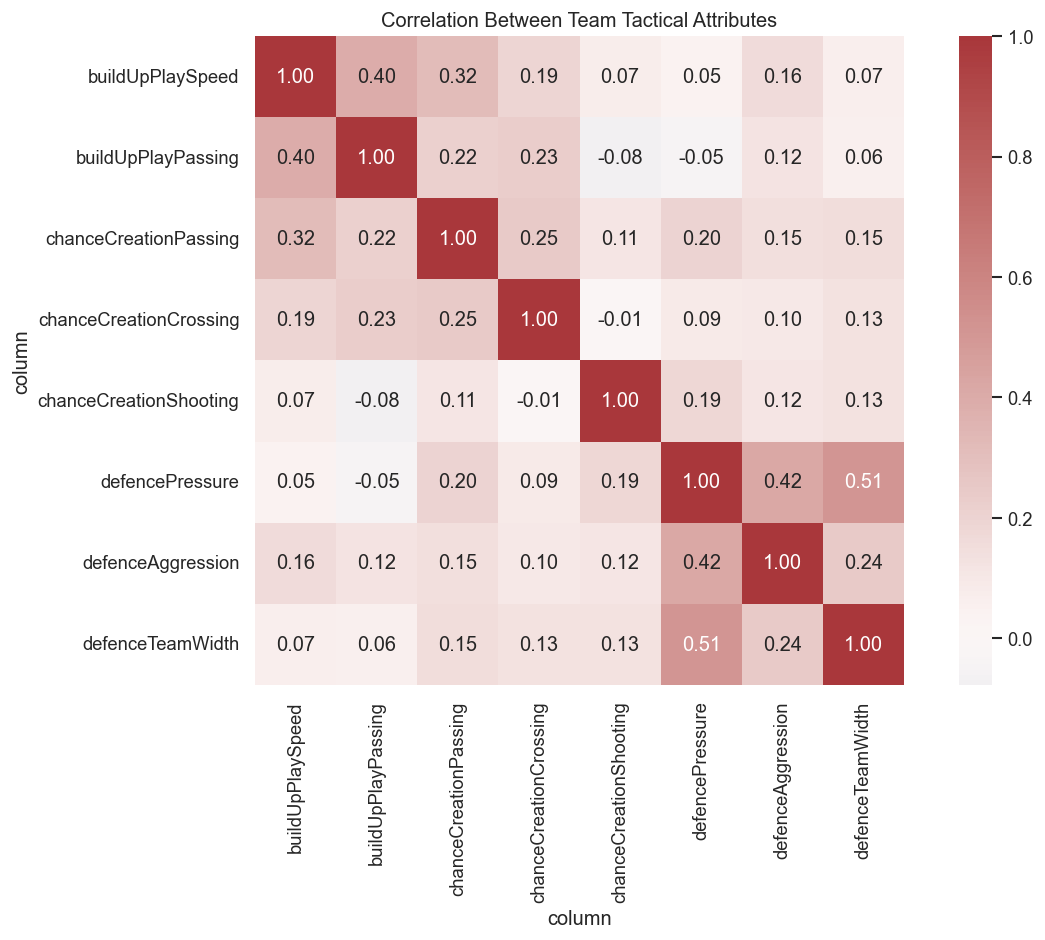

In [14]:
team_tactical_correlation = team_attributes_analysis[
    tactical_features
].corr()
display(team_tactical_correlation.round(2))

plt.figure(figsize=(11, 8))
sns.heatmap(
    team_tactical_correlation,
    annot=True,
    fmt=".2f",
    cmap="vlag",
    center=0,
    square=True,
)
plt.title("Correlation Between Team Tactical Attributes")
plt.tight_layout()
plt.savefig(
    FIGURES_DIR / "team_tactical_correlations.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()


### Team_Attributes Finding

Most tactical relationships are weak or moderate. The largest displayed relationships include defensive pressure with defensive width (0.51), defensive pressure with aggression (0.42), and build-up speed with build-up passing (0.40). Later preprocessing and feature selection should consider this overlap without assuming that correlation alone makes a variable invalid.


## 6. Player Table

One row in `Player` represents one player identity with a name, birthday, height and weight. `player_api_id`, rather than the name, is the key used in Match line-ups and Player_Attributes.


### 6.1 Structure, Missing Values and Duplicate Names

Two different people can share a name, so repeated names should be inspected but must not be removed as duplicate rows without supporting evidence.


In [15]:
player_analysis = player_df.copy()
player_analysis["birthday"] = pd.to_datetime(player_analysis["birthday"])

duplicate_player_names = player_analysis[
    player_analysis["player_name"].duplicated(keep=False)
].sort_values("player_name")

player_quality = pd.DataFrame(
    {
        "measure": [
            "Rows",
            "Columns",
            "Total missing values",
            "Duplicate rows",
            "Duplicate player IDs",
            "Repeated-name occurrences after the first",
            "Rows belonging to a repeated name",
            "Oldest birthday",
            "Youngest birthday",
        ],
        "value": [
            player_analysis.shape[0],
            player_analysis.shape[1],
            player_analysis.isna().sum().sum(),
            player_analysis.duplicated().sum(),
            player_analysis["player_api_id"].duplicated().sum(),
            player_analysis["player_name"].duplicated().sum(),
            len(duplicate_player_names),
            player_analysis["birthday"].min().date(),
            player_analysis["birthday"].max().date(),
        ],
    }
)

display(player_analysis.head())
display(player_quality)
display(duplicate_player_names.head(12))


,id,player_api_id,player_name,player_fifa_api_id,birthday,height,weight
0,1,505942,Aaron Appindangoye,218353,1992-02-29,182.88,187
1,2,155782,Aaron Cresswell,189615,1989-12-15,170.18,146
2,3,162549,Aaron Doran,186170,1991-05-13,170.18,163
3,4,30572,Aaron Galindo,140161,1982-05-08,182.88,198
4,5,23780,Aaron Hughes,17725,1979-11-08,182.88,154


,measure,value
0,Rows,11060
1,Columns,7
2,Total missing values,0
3,Duplicate rows,0
4,Duplicate player IDs,0
5,Repeated-name occurrences after the first,212
6,Rows belonging to a repeated name,375
7,Oldest birthday,1967-01-23
8,Youngest birthday,1999-04-24


,id,player_api_id,player_name,player_fifa_api_id,birthday,height,weight
84,85,26331,Adailton,158505,1983-04-14,190.50,187
85,86,41749,Adailton,4769,1977-01-24,175.26,161
98,99,23133,Adam Drury,101882,1978-08-29,180.34,161
99,100,420209,Adam Drury,205162,1993-09-09,177.80,152
137,138,181211,Adama Traore,193177,1990-02-03,170.18,161
138,139,533212,Adama Traore,225151,1995-06-28,177.80,159
190,191,121923,Adriano,183243,1982-01-21,175.26,168
191,192,30690,Adriano,106019,1982-02-17,187.96,194
192,193,33992,Adriano,164082,1984-10-26,172.72,161
193,194,41109,Adriano,152769,1980-01-29,182.88,176


### Finding

The Player table contains 11,060 complete, unique player-ID rows. There are 212 repeated-name occurrences after the first, covering 375 displayed-name rows, but the IDs, birthdays and FIFA IDs show that these are not automatically duplicate people.


### 6.2 Height and Weight

Physical measurements are inspected for their ranges, distributions and relationship. Extreme but plausible values should be verified rather than removed only because they are rare.


,count,mean,std,min,25%,50%,75%,max
height,11060.0,181.87,6.37,157.48,177.8,182.88,185.42,208.28
weight,11060.0,168.38,14.99,117.00,159.0,168.00,179.00,243.00


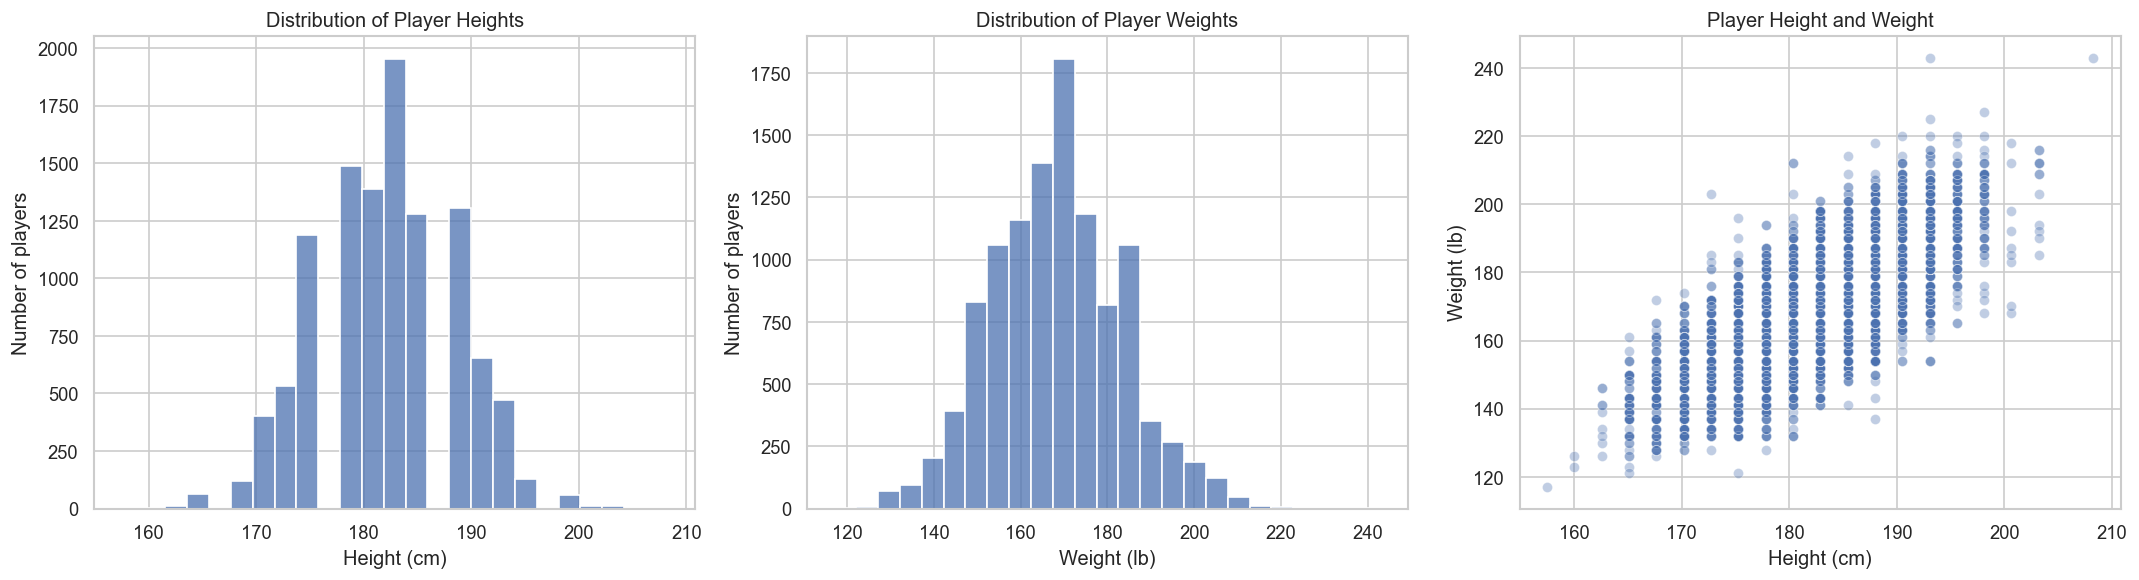

In [16]:
player_physical_summary = player_analysis[["height", "weight"]].describe().T
display(player_physical_summary.round(2))

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.histplot(player_analysis["height"], bins=25, ax=axes[0])
axes[0].set_title("Distribution of Player Heights")
axes[0].set_xlabel("Height (cm)")
axes[0].set_ylabel("Number of players")

sns.histplot(player_analysis["weight"], bins=25, ax=axes[1])
axes[1].set_title("Distribution of Player Weights")
axes[1].set_xlabel("Weight (lb)")
axes[1].set_ylabel("Number of players")

sns.scatterplot(
    data=player_analysis,
    x="height",
    y="weight",
    alpha=0.35,
    ax=axes[2],
)
axes[2].set_title("Player Height and Weight")
axes[2].set_xlabel("Height (cm)")
axes[2].set_ylabel("Weight (lb)")

fig.tight_layout()
fig.savefig(
    FIGURES_DIR / "player_physical_characteristics.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()

player_summary = pd.DataFrame(
    {
        "total_players": [len(player_analysis)],
        "missing_values": [player_analysis.isna().sum().sum()],
        "duplicate_player_ids": [
            player_analysis["player_api_id"].duplicated().sum()
        ],
        "average_height": [player_analysis["height"].mean()],
        "average_weight": [player_analysis["weight"].mean()],
    }
)
player_summary.to_csv(TABLES_DIR / "player_summary.csv", index=False)


### Player-Table Finding

Height averages 181.87 cm and ranges from 157.48 to 208.28 cm. Weight averages 168.38 lb and ranges from 117 to 243 lb. The scatter plot shows the expected positive relationship between height and weight; the endpoints are unusual observations to retain unless independent evidence shows an error.


## 7. Player_Attributes Table

One row in `Player_Attributes` represents one player's football ratings on a particular date. Multiple rows per player are expected because ratings change over time.

As with team attributes, a predictive join must use only a record dated before the match. The table even contains records after the final match date, making a correct historical join essential.


### 7.1 Structure, History and Missing Values

We check whether historical rows and row IDs are unique, whether every player is represented, how many records each player has, and which fields are incomplete.


In [17]:
player_attributes_analysis = player_attributes_df.copy()
player_attributes_analysis["date"] = pd.to_datetime(
    player_attributes_analysis["date"]
)

player_attribute_missing = pd.DataFrame(
    {
        "missing_count": player_attributes_analysis.isna().sum(),
        "missing_percentage": player_attributes_analysis.isna().mean() * 100,
    }
)
player_attribute_missing.index.name = "column"
player_attribute_missing = player_attribute_missing.sort_values(
    "missing_count", ascending=False
)
player_attribute_missing.reset_index().to_csv(
    TABLES_DIR / "player_attributes_missing_values.csv", index=False
)

player_attribute_record_counts = player_attributes_analysis[
    "player_api_id"
].value_counts()

player_attribute_quality = pd.DataFrame(
    {
        "measure": [
            "Rows",
            "Columns",
            "Duplicate rows",
            "Duplicate row IDs",
            "Players represented",
            "Players in Player lookup",
            "First record",
            "Last record",
            "Minimum records per player",
            "Median records per player",
            "Maximum records per player",
        ],
        "value": [
            player_attributes_analysis.shape[0],
            player_attributes_analysis.shape[1],
            player_attributes_analysis.duplicated().sum(),
            player_attributes_analysis["id"].duplicated().sum(),
            player_attributes_analysis["player_api_id"].nunique(),
            player_analysis["player_api_id"].nunique(),
            player_attributes_analysis["date"].min().date(),
            player_attributes_analysis["date"].max().date(),
            player_attribute_record_counts.min(),
            player_attribute_record_counts.median(),
            player_attribute_record_counts.max(),
        ],
    }
)

display(player_attributes_analysis.head())
display(player_attribute_quality)
display(
    player_attribute_missing.query("missing_count > 0").round(3)
)


column,id,player_fifa_api_id,player_api_id,date,overall_rating,potential,preferred_foot,attacking_work_rate,defensive_work_rate,crossing,...,vision,penalties,marking,standing_tackle,sliding_tackle,gk_diving,gk_handling,gk_kicking,gk_positioning,gk_reflexes
0,1,218353,505942,2016-02-18,67.0,71.0,right,medium,medium,49.0,...,54.0,48.0,65.0,69.0,69.0,6.0,11.0,10.0,8.0,8.0
1,2,218353,505942,2015-11-19,67.0,71.0,right,medium,medium,49.0,...,54.0,48.0,65.0,69.0,69.0,6.0,11.0,10.0,8.0,8.0
2,3,218353,505942,2015-09-21,62.0,66.0,right,medium,medium,49.0,...,54.0,48.0,65.0,66.0,69.0,6.0,11.0,10.0,8.0,8.0
3,4,218353,505942,2015-03-20,61.0,65.0,right,medium,medium,48.0,...,53.0,47.0,62.0,63.0,66.0,5.0,10.0,9.0,7.0,7.0
4,5,218353,505942,2007-02-22,61.0,65.0,right,medium,medium,48.0,...,53.0,47.0,62.0,63.0,66.0,5.0,10.0,9.0,7.0,7.0


,measure,value
0,Rows,183978
1,Columns,42
2,Duplicate rows,0
3,Duplicate row IDs,0
4,Players represented,11060
5,Players in Player lookup,11060
6,First record,2007-02-22
7,Last record,2016-07-07
8,Minimum records per player,2
9,Median records per player,16.0


,missing_count,missing_percentage
column,,
attacking_work_rate,6869,3.734
agility,2713,1.475
jumping,2713,1.475
curve,2713,1.475
volleys,2713,1.475
balance,2713,1.475
vision,2713,1.475
sliding_tackle,2713,1.475
standing_tackle,836,0.454


### Finding

The table has 183,978 unique historical rows for all 11,060 players, with 2 to 56 records per player. Dates span 22 February 2007 to 7 July 2016. Missingness is limited but patterned: `attacking_work_rate` has 6,869 missing values (3.73%); seven fields have 2,713 missing values (1.47%); and many other rating fields have 836 missing values (0.45%). These patterns should be handled in Notebook 03 rather than silently dropping rows here.


### 7.2 Ratings and Potential

Overall rating summarizes current ability, while potential estimates possible future ability. Their distributions and relationship help reveal typical values, extremes and redundancy.


,count,mean,std,min,25%,50%,75%,max
column,,,,,,,,
overall_rating,183142.0,68.60,7.04,33.0,64.0,69.0,73.0,94.0
potential,183142.0,73.46,6.59,39.0,69.0,74.0,78.0,97.0


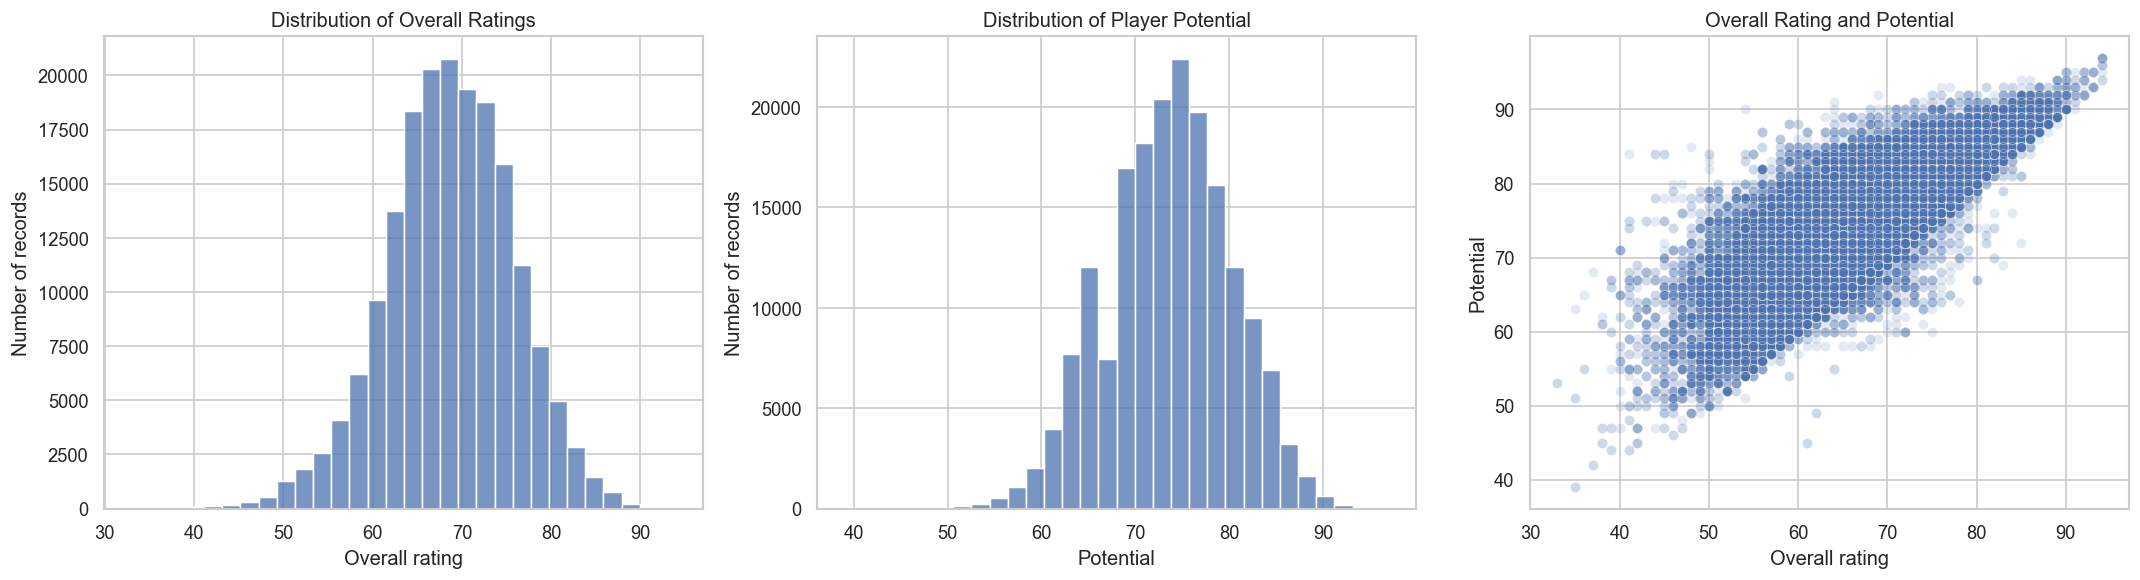

In [18]:
rating_summary = player_attributes_analysis[
    ["overall_rating", "potential"]
].describe().T
display(rating_summary.round(2))

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.histplot(
    player_attributes_analysis["overall_rating"], bins=30, ax=axes[0]
)
axes[0].set_title("Distribution of Overall Ratings")
axes[0].set_xlabel("Overall rating")
axes[0].set_ylabel("Number of records")

sns.histplot(player_attributes_analysis["potential"], bins=30, ax=axes[1])
axes[1].set_title("Distribution of Player Potential")
axes[1].set_xlabel("Potential")
axes[1].set_ylabel("Number of records")

sns.scatterplot(
    data=player_attributes_analysis,
    x="overall_rating",
    y="potential",
    alpha=0.15,
    ax=axes[2],
)
axes[2].set_title("Overall Rating and Potential")
axes[2].set_xlabel("Overall rating")
axes[2].set_ylabel("Potential")

fig.tight_layout()
fig.savefig(
    FIGURES_DIR / "player_rating_distributions.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()


### Finding

Overall rating averages 68.60 and ranges from 33 to 94. Potential averages 73.46 and ranges from 39 to 97. The upward relationship in the scatter plot is expected because stronger players also tend to have higher potential, but the measures are not identical.


### 7.3 Categorical Values and Data Quality

We inspect preferred foot and work-rate categories. Unexpected strings may represent source-data corruption or encoding problems; EDA records the issue without deciding the final cleaning rule.


,preferred_foot,records
0,right,138409
1,left,44733
2,NaN,836


,attacking_work_rate,records
0,medium,125070
1,high,42823
2,low,8569
3,NaN,6869
4,norm,348
5,y,106
6,le,104
7,stoc,89


,defensive_work_rate,records
0,medium,130846
1,high,27041
2,low,18432
3,_0,2394
4,o,1550
5,NaN,836
6,1,441
7,ormal,348
8,2,342
9,3,258


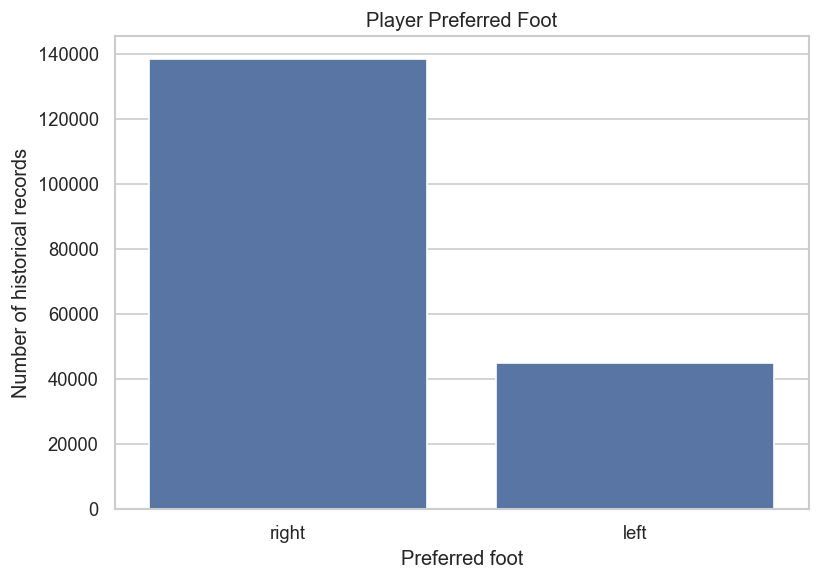

In [19]:
preferred_foot_counts = (
    player_attributes_analysis["preferred_foot"]
    .value_counts(dropna=False)
    .rename_axis("preferred_foot")
    .reset_index(name="records")
)
attacking_work_rate_counts = (
    player_attributes_analysis["attacking_work_rate"]
    .value_counts(dropna=False)
    .rename_axis("attacking_work_rate")
    .reset_index(name="records")
)
defensive_work_rate_counts = (
    player_attributes_analysis["defensive_work_rate"]
    .value_counts(dropna=False)
    .rename_axis("defensive_work_rate")
    .reset_index(name="records")
)

display(preferred_foot_counts)
display(attacking_work_rate_counts)
display(defensive_work_rate_counts)

plt.figure(figsize=(7, 5))
sns.barplot(
    data=preferred_foot_counts.dropna(),
    x="preferred_foot",
    y="records",
    color="#4C72B0",
)
plt.title("Player Preferred Foot")
plt.xlabel("Preferred foot")
plt.ylabel("Number of historical records")
plt.tight_layout()
plt.savefig(
    FIGURES_DIR / "player_preferred_foot.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()


### Finding

Right-footed records dominate: 138,409 (75.57%) versus 44,733 left-footed records (24.43%). The work-rate columns also contain malformed fragments such as `norm`, `stoc`, `_0`, single letters and digits in addition to high/medium/low. These values need an explicit cleaning decision later and should not be mistaken for meaningful football categories.


### 7.4 Correlation Between Player Attributes

Player attributes can be strongly related because they describe connected skills or different playing positions. We examine a representative set rather than all 35 numerical rating columns at once.


column,overall_rating,potential,finishing,short_passing,dribbling,acceleration,sprint_speed,strength,interceptions,standing_tackle,gk_reflexes
count,183142.00,183142.00,183142.00,183142.00,183142.00,183142.00,183142.00,183142.00,183142.00,183142.00,183142.00
mean,68.60,73.46,49.92,62.43,59.18,67.66,68.05,67.42,52.01,50.35,16.44
std,7.04,6.59,19.04,14.19,17.74,12.98,12.57,12.07,19.45,21.48,17.20
min,33.00,39.00,1.00,3.00,1.00,10.00,12.00,10.00,1.00,1.00,1.00
25%,64.00,69.00,34.00,57.00,52.00,61.00,62.00,60.00,34.00,29.00,8.00
50%,69.00,74.00,53.00,65.00,64.00,69.00,69.00,69.00,57.00,56.00,11.00
75%,73.00,78.00,65.00,72.00,72.00,77.00,77.00,76.00,68.00,69.00,15.00
max,94.00,97.00,97.00,97.00,97.00,97.00,97.00,96.00,96.00,95.00,96.00


column,overall_rating,potential,finishing,short_passing,dribbling,acceleration,sprint_speed,strength,interceptions,standing_tackle,gk_reflexes
column,,,,,,,,,,,
overall_rating,1.00,0.77,0.33,0.46,0.35,0.25,0.25,0.32,0.25,0.17,0.01
potential,0.77,1.00,0.29,0.38,0.34,0.34,0.34,0.13,0.17,0.08,0.00
finishing,0.33,0.29,1.00,0.58,0.78,0.53,0.51,-0.05,-0.15,-0.23,-0.47
short_passing,0.46,0.38,0.58,1.00,0.79,0.50,0.49,0.09,0.42,0.42,-0.69
dribbling,0.35,0.34,0.78,0.79,1.00,0.70,0.67,-0.11,0.11,0.07,-0.66
acceleration,0.25,0.34,0.53,0.50,0.70,1.00,0.90,-0.21,0.02,-0.00,-0.47
sprint_speed,0.25,0.34,0.51,0.49,0.67,0.90,1.00,-0.11,0.05,0.04,-0.49
strength,0.32,0.13,-0.05,0.09,-0.11,-0.21,-0.11,1.00,0.34,0.37,-0.08
interceptions,0.25,0.17,-0.15,0.42,0.11,0.02,0.05,0.34,1.00,0.84,-0.33


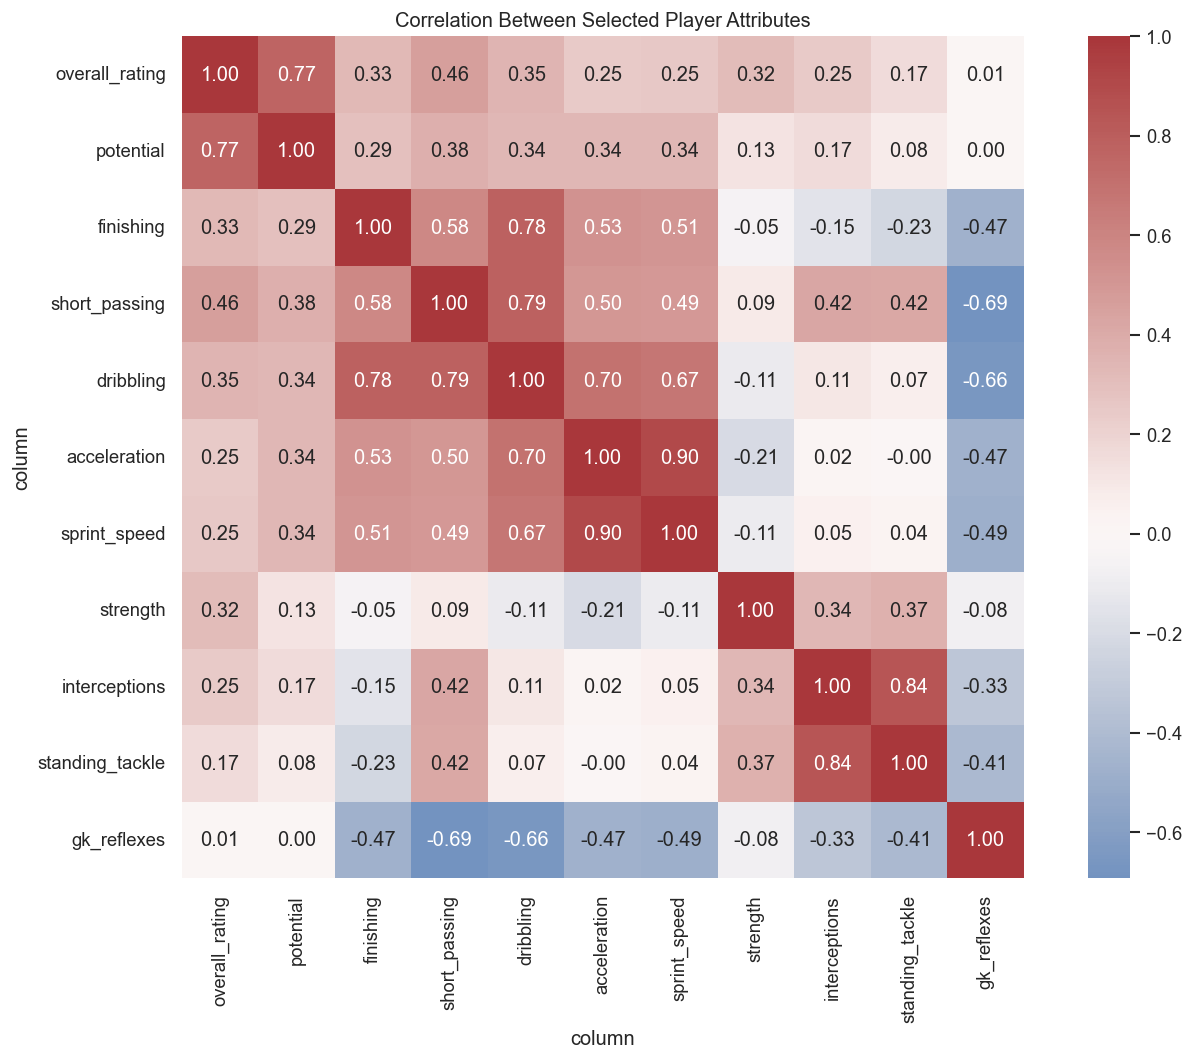

In [20]:
important_player_features = [
    "overall_rating",
    "potential",
    "finishing",
    "short_passing",
    "dribbling",
    "acceleration",
    "sprint_speed",
    "strength",
    "interceptions",
    "standing_tackle",
    "gk_reflexes",
]

player_attributes_summary = player_attributes_analysis[
    important_player_features
].describe()
player_attributes_summary.to_csv(
    TABLES_DIR / "player_attributes_summary.csv"
)
display(player_attributes_summary.round(2))

player_attribute_correlation = player_attributes_analysis[
    important_player_features
].corr()
display(player_attribute_correlation.round(2))

plt.figure(figsize=(12, 9))
sns.heatmap(
    player_attribute_correlation,
    annot=True,
    fmt=".2f",
    cmap="vlag",
    center=0,
    square=True,
)
plt.title("Correlation Between Selected Player Attributes")
plt.tight_layout()
plt.savefig(
    FIGURES_DIR / "player_attribute_correlations.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()


### Finding

Several strong relationships appear: acceleration with sprint speed (0.90), interceptions with standing tackle (0.84), short passing with dribbling (0.79), finishing with dribbling (0.78), and overall rating with potential (0.77). Goalkeeper reflexes are negatively related to several outfield skills because goalkeepers have a different role. These correlations reveal redundancy and position structure, but feature-removal decisions belong to later feature analysis.


### 7.5 Ratings Over Time

Average ratings by calendar year can reveal changes in database coverage or rating conventions. This trend should not automatically be interpreted as all footballers improving.


year
2007    64.556
2008    66.988
2009    68.237
2010    68.172
2011    68.472
2012    68.536
2013    68.969
2014    68.944
2015    69.578
2016    70.382
Name: average_overall_rating, dtype: float64

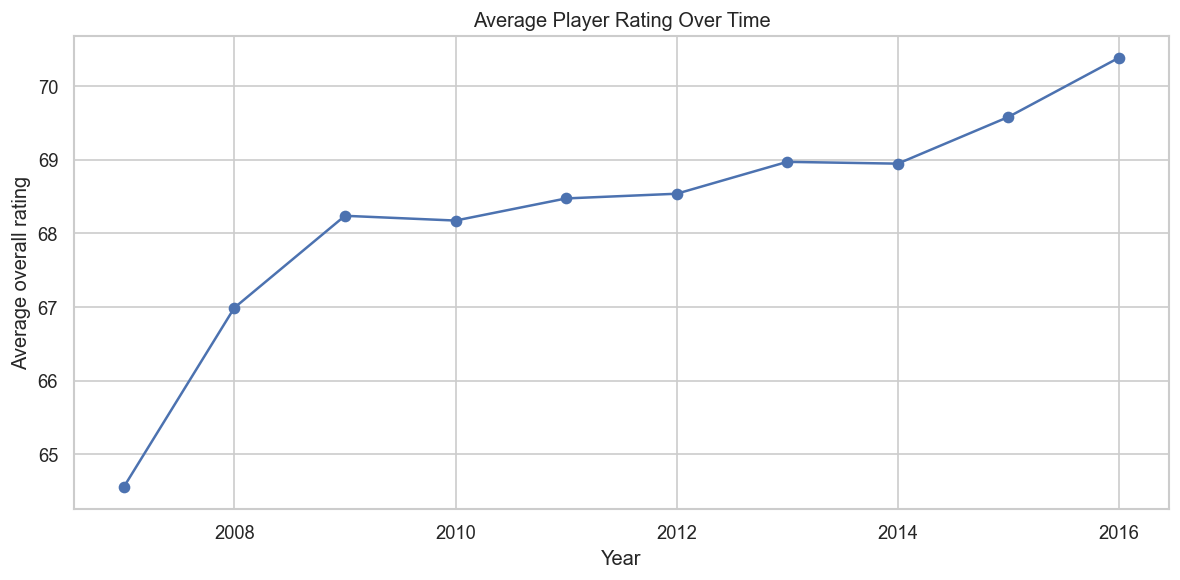

In [21]:
rating_by_year = (
    player_attributes_analysis.assign(
        year=player_attributes_analysis["date"].dt.year
    )
    .groupby("year")["overall_rating"]
    .mean()
)

display(rating_by_year.rename("average_overall_rating").round(3))

rating_by_year.plot(kind="line", marker="o", figsize=(10, 5))
plt.title("Average Player Rating Over Time")
plt.xlabel("Year")
plt.ylabel("Average overall rating")
plt.tight_layout()
plt.savefig(
    FIGURES_DIR / "player_rating_over_time.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()


### Player_Attributes Finding

The annual mean rises from 64.56 in 2007 to 70.38 in 2016. This may reflect changing player coverage, rating conventions or the composition of recorded players, so it is a descriptive database trend rather than proof of improving player ability.


## 8. League and Country Tables

One row in `Country` represents a country, and one row in `League` represents a competition linked to its country by `country_id`. These are small reference tables used to turn IDs into readable context.


### 8.1 Completeness, Uniqueness and Relationship

We check both lookup tables before joining them. This ordering ensures every variable is defined before use and verifies that all league-to-country links resolve.


In [22]:
reference_quality = pd.DataFrame(
    {
        "table": ["League", "Country"],
        "rows": [len(league_df), len(country_df)],
        "columns": [league_df.shape[1], country_df.shape[1]],
        "missing_values": [
            league_df.isna().sum().sum(),
            country_df.isna().sum().sum(),
        ],
        "duplicate_ids": [
            league_df["id"].duplicated().sum(),
            country_df["id"].duplicated().sum(),
        ],
        "duplicate_names": [
            league_df["name"].duplicated().sum(),
            country_df["name"].duplicated().sum(),
        ],
    }
)

league_country = league_df.merge(
    country_df,
    left_on="country_id",
    right_on="id",
    how="left",
    suffixes=("_league", "_country"),
    validate="many_to_one",
)

display(reference_quality)
display(
    league_country[["name_league", "name_country"]].rename(
        columns={"name_league": "league", "name_country": "country"}
    )
)
print(
    "League country IDs successfully matched:",
    league_df["country_id"].isin(country_df["id"]).sum(),
    "of",
    len(league_df),
)


,table,rows,columns,missing_values,duplicate_ids,duplicate_names
0,League,11,3,0,0,0
1,Country,11,2,0,0,0


,league,country
0,Belgium Jupiler League,Belgium
1,England Premier League,England
2,France Ligue 1,France
3,Germany 1. Bundesliga,Germany
4,Italy Serie A,Italy
5,Netherlands Eredivisie,Netherlands
6,Poland Ekstraklasa,Poland
7,Portugal Liga ZON Sagres,Portugal
8,Scotland Premier League,Scotland
9,Spain LIGA BBVA,Spain


League country IDs successfully matched: 11 of 11


### League-and-Country Finding

Both lookup tables contain 11 complete rows with unique IDs and names, and all 11 league-to-country relationships resolve. Their numerical IDs encode identity, not magnitude: for example, a larger league ID does not mean a stronger league.


## 9. Final Engineered Supervised Modelling Dataset

The source-table EDA above explains the raw database. This concise section audits the actual one-row-per-match dataset handed to modelling.

The retention and integrity checks use all six modelling seasons because they describe dataset construction. Feature/target plots use only the development period, **2010/11–2014/15**. The 2015/16 test season is excluded from exploratory feature evidence and is not used for preprocessing, feature, model, or hyperparameter decisions.

In [23]:
ENGINEERED_PATH = PROJECT_ROOT / "data" / "processed" / "model_data_engineered.csv"
RETENTION_PATH = TABLES_DIR / "data_retention.csv"

engineered_data = pd.read_csv(ENGINEERED_PATH, low_memory=False)
data_retention = pd.read_csv(RETENTION_PATH)

identifier_columns = [
    "id", "match_api_id", "country_id", "league_id",
    "home_team_api_id", "away_team_api_id",
]
leakage_columns = ["home_team_goal", "away_team_goal"]
metadata_columns = ["date", "country_name", "home_team_name", "away_team_name"]
player_id_columns = [f"home_player_{i}" for i in range(1, 12)] + [
    f"away_player_{i}" for i in range(1, 12)
]
player_position_columns = [
    column for column in engineered_data.columns
    if "player_X" in column or "player_Y" in column
]
attribute_date_columns = ["home_team_attr_date", "away_team_attr_date"]
excluded_columns = (
    identifier_columns + leakage_columns + metadata_columns + player_id_columns
    + player_position_columns + attribute_date_columns + ["target"]
)
candidate_data = engineered_data.drop(columns=excluded_columns)

engineered_audit = pd.DataFrame(
    {
        "metric": [
            "Final usable matches",
            "Candidate features before encoding",
            "Missing candidate values",
            "Duplicate match IDs",
            "Leagues represented",
            "Seasons represented",
            "Numeric candidate features",
            "Categorical candidate features",
            "Home Win percent",
            "Draw percent",
            "Away Win percent",
        ],
        "value": [
            len(engineered_data),
            candidate_data.shape[1],
            int(candidate_data.isna().sum().sum()),
            int(engineered_data["id"].duplicated().sum()),
            engineered_data["league_name"].nunique(),
            engineered_data["season"].nunique(),
            candidate_data.select_dtypes(include="number").shape[1],
            candidate_data.select_dtypes(exclude="number").shape[1],
            engineered_data["target"].eq("Home Win").mean() * 100,
            engineered_data["target"].eq("Draw").mean() * 100,
            engineered_data["target"].eq("Away Win").mean() * 100,
        ],
    }
)
engineered_audit.to_csv(TABLES_DIR / "engineered_dataset_audit.csv", index=False)

display(engineered_audit.round(2))
display(data_retention.round(2))
display(pd.crosstab(engineered_data["season"], engineered_data["league_name"]))

assert len(engineered_data) == 17_609
assert candidate_data.shape[1] == 75
assert candidate_data.isna().sum().sum() == 0
assert engineered_data["id"].duplicated().sum() == 0

,metric,value
0,Final usable matches,17609.00
1,Candidate features before encoding,75.00
2,Missing candidate values,0.00
3,Duplicate match IDs,0.00
4,Leagues represented,11.00
5,Seasons represented,6.00
6,Numeric candidate features,65.00
7,Categorical candidate features,10.00
8,Home Win percent,45.58
9,Draw percent,25.31


,stage,matches_retained,matches_removed_at_stage,percent_of_raw_retained
0,Raw Match table,25979,0,100.00
1,Keep 2010/11–2015/16,19423,6556,74.76
2,Require historical team attributes,18268,1155,70.32
3,Require five previous matches for form,18016,252,69.35
4,Require at least eight rated players per side,17609,407,67.78


league_name,Belgium Jupiler League,England Premier League,France Ligue 1,Germany 1. Bundesliga,Italy Serie A,Netherlands Eredivisie,Poland Ekstraklasa,Portugal Liga ZON Sagres,Scotland Premier League,Spain LIGA BBVA,Switzerland Super League
season,,,,,,,,,,,
2010/2011,186,375,370,296,370,259,24,191,202,365,159
2011/2012,190,365,367,301,353,306,66,192,201,370,153
2012/2013,210,370,366,297,375,272,162,182,155,375,180
2013/2014,6,370,375,301,371,235,203,207,185,375,180
2014/2015,203,375,375,301,374,263,203,236,223,370,144
2015/2016,234,370,371,296,370,306,203,238,228,375,138


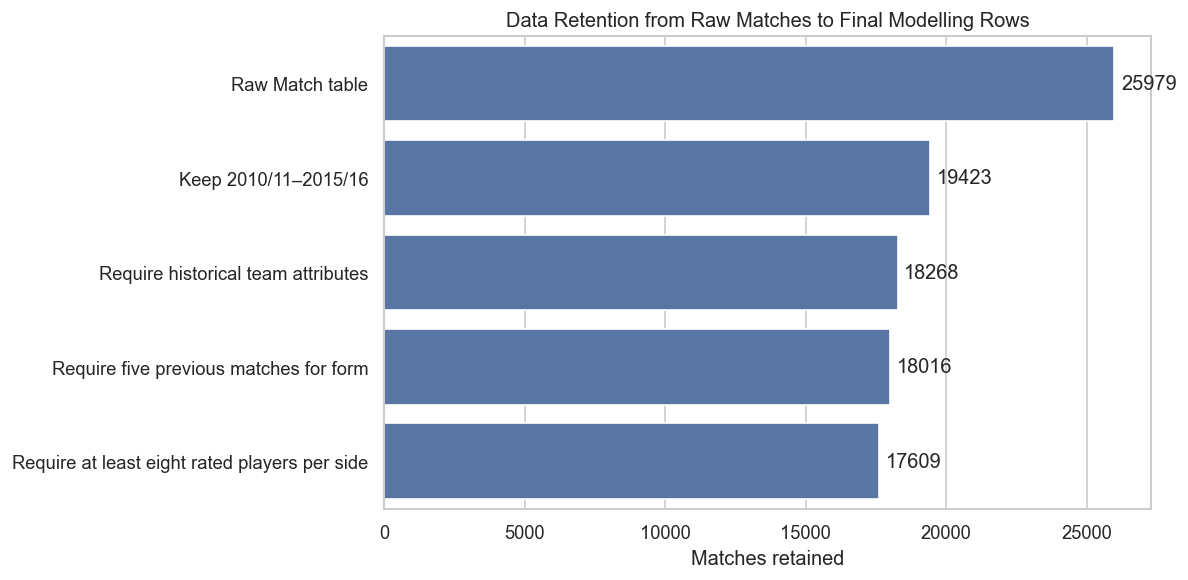

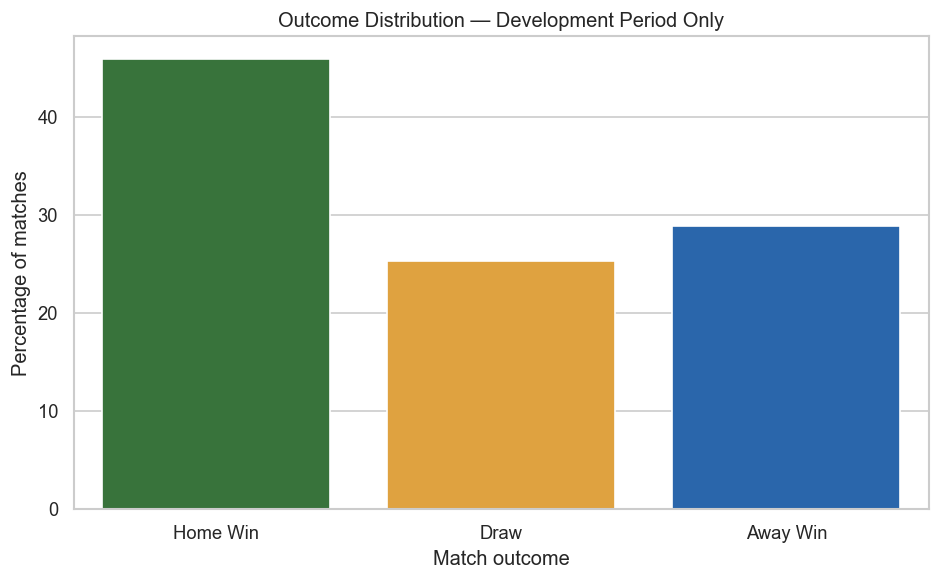

In [24]:
fig, axis = plt.subplots(figsize=(10, 5))
retention_plot = data_retention.copy()
sns.barplot(
    data=retention_plot,
    x="matches_retained",
    y="stage",
    color="#4C72B0",
    ax=axis,
)
axis.set_title("Data Retention from Raw Matches to Final Modelling Rows")
axis.set_xlabel("Matches retained")
axis.set_ylabel("")
for container in axis.containers:
    axis.bar_label(container, fmt="%d", padding=4)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "data_retention.png", dpi=300, bbox_inches="tight")
plt.show()

development_data = engineered_data.loc[
    engineered_data["season"] != "2015/2016"
].copy()
development_target = (
    development_data["target"]
    .value_counts()
    .reindex(["Home Win", "Draw", "Away Win"])
    .rename_axis("target")
    .reset_index(name="matches")
)
development_target["percentage"] = (
    development_target["matches"] / development_target["matches"].sum() * 100
)

fig, axis = plt.subplots(figsize=(8, 5))
sns.barplot(
    data=development_target,
    x="target",
    y="percentage",
    hue="target",
    palette=["#2E7D32", "#F9A825", "#1565C0"],
    legend=False,
    ax=axis,
)
axis.set_title("Outcome Distribution — Development Period Only")
axis.set_xlabel("Match outcome")
axis.set_ylabel("Percentage of matches")
fig.tight_layout()
fig.savefig(
    FIGURES_DIR / "engineered_target_distribution.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()

### Retention and integrity finding

The usable sample falls from 25,979 raw matches to 17,609 modelling matches. The largest intentional reduction selects the six seasons with historical tactical coverage; later filters require a historical tactical snapshot, five previous matches for form, and at least eight historically rated players for each side. The final 75 candidate columns contain no missing values and match IDs remain unique.

All candidate variables are available before kickoff under the preserved workflow: tactical and player snapshots use backward date joins, recent form uses a one-match shift, and final scores/event fields are excluded. Same-calendar-date attribute snapshots remain a documented source limitation because the database supplies dates but not event times.

overall_rating_diff               form_points_diff                \
                        mean median    std             mean median    std   
target                                                                      
Home Win               1.901  1.727  4.737            0.787    1.0  4.613   
Draw                  -0.377 -0.273  4.479           -0.599   -1.0  4.381   
Away Win              -2.474 -2.364  4.755           -1.657   -2.0  4.533   

         attack_diff               defence_diff               passing_diff  \
                mean median    std         mean median    std         mean   
target                                                                       
Home Win       2.180  2.075  5.964        0.675  0.600  5.232        2.076   
Draw          -0.365 -0.375  5.756       -0.577 -0.650  5.244       -0.479   
Away Win      -2.470 -2.275  5.891       -1.683 -1.747  5.328       -2.751   

                        
         median    std  
target                  
Home Win  2.000  5.555  
Draw     -0.367  5.324  
Away Win -2.667  5.597

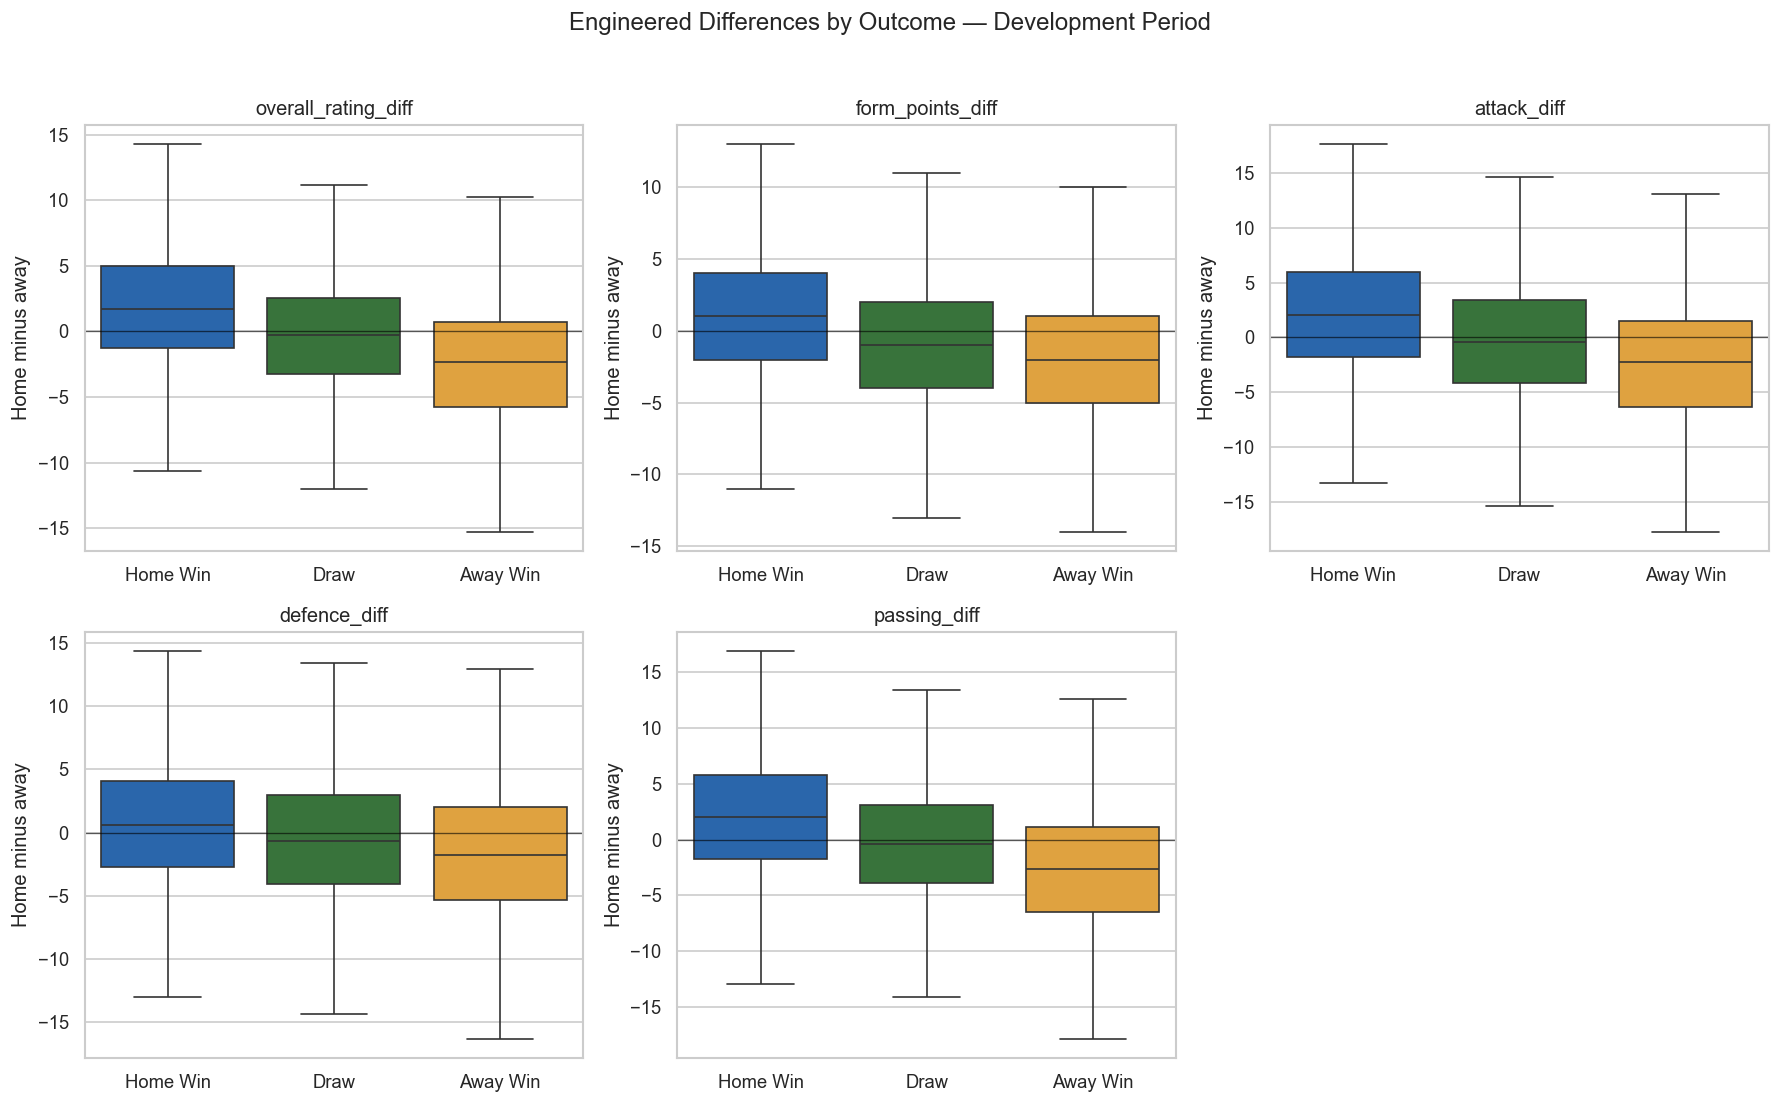

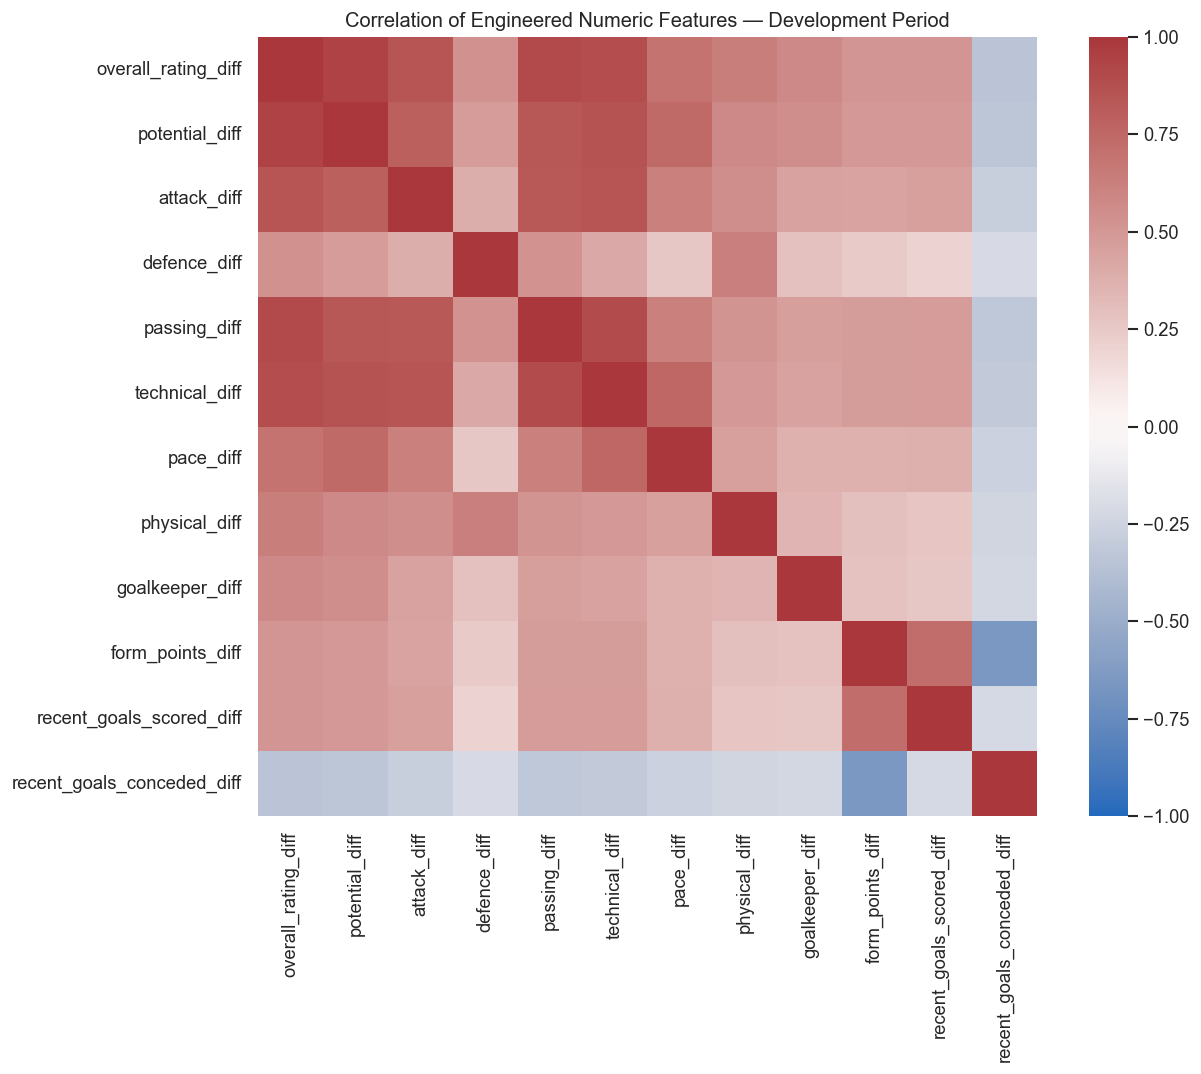

In [25]:
engineered_features = [
    "overall_rating_diff",
    "form_points_diff",
    "attack_diff",
    "defence_diff",
    "passing_diff",
]
target_order = ["Home Win", "Draw", "Away Win"]

feature_target_summary = (
    development_data.groupby("target")[engineered_features]
    .agg(["mean", "median", "std"])
    .reindex(target_order)
)
feature_target_summary.to_csv(TABLES_DIR / "engineered_feature_target_summary.csv")
display(feature_target_summary.round(3))

long_features = development_data.melt(
    id_vars="target",
    value_vars=engineered_features,
    var_name="feature",
    value_name="home_minus_away_value",
)
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
for axis, feature in zip(axes.flat, engineered_features):
    sns.boxplot(
        data=long_features.loc[long_features["feature"] == feature],
        x="target",
        y="home_minus_away_value",
        order=target_order,
        hue="target",
        palette=["#2E7D32", "#F9A825", "#1565C0"],
        legend=False,
        showfliers=False,
        ax=axis,
    )
    axis.axhline(0, color="black", linewidth=0.8, alpha=0.6)
    axis.set_title(feature)
    axis.set_xlabel("")
    axis.set_ylabel("Home minus away")
axes.flat[-1].axis("off")
fig.suptitle("Engineered Differences by Outcome — Development Period", y=1.02)
fig.tight_layout()
fig.savefig(
    FIGURES_DIR / "engineered_features_by_outcome.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()

correlation_features = [
    "overall_rating_diff", "potential_diff", "attack_diff", "defence_diff",
    "passing_diff", "technical_diff", "pace_diff", "physical_diff",
    "goalkeeper_diff", "form_points_diff", "recent_goals_scored_diff",
    "recent_goals_conceded_diff",
]
engineered_correlation = development_data[correlation_features].corr()
engineered_correlation.to_csv(TABLES_DIR / "engineered_feature_correlations.csv")

fig, axis = plt.subplots(figsize=(11, 9))
sns.heatmap(
    engineered_correlation,
    cmap="vlag",
    center=0,
    vmin=-1,
    vmax=1,
    square=True,
    ax=axis,
)
axis.set_title("Correlation of Engineered Numeric Features — Development Period")
fig.tight_layout()
fig.savefig(
    FIGURES_DIR / "engineered_feature_correlation.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()

### Engineered-feature finding

Home-minus-away rating, attack, defence, and passing differences shift in the expected direction across outcomes, while Draws concentrate more closely around balanced team strength. Several squad-strength differences are strongly correlated, which supports later feature-selection and redundancy checks rather than automatic removal during EDA. Recent form contributes a different, shorter-term view of relative strength.

These plots are descriptive evidence from training plus validation seasons only. They do not inspect the 2015/16 test outcomes and therefore do not influence decisions using the final holdout.

## 9. Overall EDA Findings

The analysis can be summarized by the modelling question each finding creates. This table records issues for the next notebook without performing the final cleaning here.


In [26]:
eda_implications = pd.DataFrame(
    {
        "topic": [
            "Target balance",
            "Core match completeness",
            "Optional match fields",
            "Historical attributes",
            "Team tactical coverage",
            "Player attribute categories",
            "Correlated features",
            "Identifiers",
            "Unusual values",
        ],
        "evidence": [
            "Home Win 45.87%, Away Win 28.74%, Draw 25.39%",
            "No missing IDs, dates, teams or final scores in core fields",
            "104 of 115 Match columns contain at least one missing value",
            "Repeated team/player IDs represent dated observations",
            "288 of 299 teams have Team_Attributes records",
            "Work-rate fields contain missing and malformed values",
            "Several tactical and player attributes are strongly related",
            "API IDs identify entities but are not continuous measurements",
            "Rare high scores and physical endpoints are internally plausible",
        ],
        "modelling_implication": [
            "Use Macro F1 as the primary metric and accuracy as secondary",
            "Retain the match rows; do not drop them for core-field missingness",
            "Choose valid predictors by meaning and availability",
            "Join only the latest record available before each match",
            "Handle unavailable historical tactics explicitly",
            "Define cleaning/encoding rules in Notebook 03",
            "Assess redundancy during later feature analysis",
            "Exclude or encode identifiers according to their role",
            "Verify before removal; do not treat rarity alone as an error",
        ],
    }
)

display(eda_implications)


,topic,evidence,modelling_implication
0,Target balance,"Home Win 45.87%, Away Win 28.74%, Draw 25.39%",Use Macro F1 as the primary metric and accurac...
1,Core match completeness,"No missing IDs, dates, teams or final scores i...",Retain the match rows; do not drop them for co...
2,Optional match fields,104 of 115 Match columns contain at least one ...,Choose valid predictors by meaning and availab...
3,Historical attributes,Repeated team/player IDs represent dated obser...,Join only the latest record available before e...
4,Team tactical coverage,288 of 299 teams have Team_Attributes records,Handle unavailable historical tactics explicitly
5,Player attribute categories,Work-rate fields contain missing and malformed...,Define cleaning/encoding rules in Notebook 03
6,Correlated features,Several tactical and player attributes are str...,Assess redundancy during later feature analysis
7,Identifiers,API IDs identify entities but are not continuo...,Exclude or encode identifiers according to the...
8,Unusual values,Rare high scores and physical endpoints are in...,Verify before removal; do not treat rarity alo...


### Data Quality and Modelling Implications

1. **Missing data:** Core match identifiers, teams and outcomes are complete, but optional Match fields are often missing. `buildUpPlayDribbling` is heavily incomplete, while Player_Attributes has smaller patterned gaps. Missingness must be handled by column role, not by deleting every incomplete row.

2. **Duplicates and repeated history:** No source table examined has duplicate row IDs or duplicate full rows. Repeated team/player IDs in attribute tables are correct dated observations. Repeated human-readable names can refer to different entities, so joins must use API IDs.

3. **Temporal data and leakage:** Match, Team_Attributes and Player_Attributes are time-dependent. Only information recorded before a match may predict it. Later records, the final score and other post-match fields would create leakage.

4. **Class imbalance:** Home Wins are more frequent than Draws and Away Wins. Macro F1 should be the primary model-selection metric because it gives equal importance to all three outcomes; accuracy should remain a secondary metric.

5. **Correlated features:** Team tactics and player skills contain related measures. Correlation can reveal redundancy, but it does not by itself prove that a predictor should be removed. Statistical and model-based feature analysis comes later.

6. **Identifiers:** Match, country, league, team and player IDs describe identity. Their numerical sizes have no natural football meaning and they should not be treated as ordinary continuous measurements.

7. **Unusual values:** High-scoring matches and extreme height/weight values are rare but plausible. Malformed work-rate strings are more likely data-quality issues. Neither type should be silently removed during EDA.

8. **Test-season protection:** This notebook describes the complete source database but does not use test results to choose preprocessing, features or models. Notebook 03 must fit preprocessing only on the training seasons, and later model experiments must keep 2015/2016 untouched.

### Transition to Notebook 03

Notebook 03 will load the engineered match-level dataset, separate valid candidate predictors from identifiers and leakage columns, apply explicit cleaning and encoding rules, and create the chronological train/validation/test datasets. The evidence above explains why those steps are necessary.
